# 02 · New training recipe: ablation, 0–1 scaling and cross-dataset test (30 epochs)

**Project:** DeFakeNet-Lite, a lightweight detector for real vs AI-generated (StyleGAN) face images
**Author:** Arman Rahman, BSc CSE, East Delta University · **Supervisor:** Md. Jamil Uddin
**Dataset:** RVF10K balanced splits (Zenodo 10.5281/zenodo.14532968), 6,000 train / 2,000 validation / 2,000 test

This notebook trains the new recipe for 30 epochs (5 frozen + 25 fine-tune) and runs:

* **core**: `MobileNetV3L_a075` (the model later named **DeFakeNet-Lite**) and `DeFakeNet_NR` (the DeFakeNet architecture, ResNet50V2 + Dense 1024, with the new recipe);
* **paper_scaling**: DeFakeNet with the paper's 0–1 pixel scaling;
* **ablation**: seven runs of `MobileNetV3L_a075`, each switching **one** part of the recipe back to the DeFakeNet paper's way;
* **seeds**: extra seeds for both models;
* a **cross-dataset** test on unseen datasets (no retraining).

The ablation and the 0–1 scaling runs are reused by notebook **03**, which trains the final 40-epoch models. The saved results of those runs are in `results/02_ablation_30_epochs/`.

## 1. Settings and imports

In [1]:
RUN_GROUPS = ["core", "paper_scaling", "ablation", "seeds"]   # all 13 runs, about 7 h on one T4
EXTERNAL_MAX_PER_CLASS = 1000   # images per class taken from each attached dataset

import os, time, json, random, gc, hashlib, glob, io, contextlib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
try: print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError: print("nvidia-smi not found (no GPU)")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU       :", tf.config.list_physical_devices("GPU"))

Mon Nov  2 19:16:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Dataset (same Zenodo record, "6040" folder = 60/20/20 split: 6000 train / 2000 valid / 2000 test)

In [2]:
import requests, zipfile
RECORD_ID = "14532968"
meta = requests.get(f"https://zenodo.org/api/records/{RECORD_ID}").json()
os.makedirs("/content/data", exist_ok=True)
for f in meta["files"]:
    dest = f"/content/{f['key']}"
    if not os.path.exists(dest):
        print("Downloading", f["key"], "...")
        subprocess.run(["wget", "-q", "-O", dest, f["links"]["self"]], check=True)
    if f["key"].lower().endswith(".zip") and not os.path.isdir("/content/data/Real vs Fake Faces"):
        print("Extracting ...")
        with zipfile.ZipFile(dest) as z:
            z.extractall("/content/data")
DATA_BASE = "/content/data"
print("Done.")

def find_split_root(base, tokens=("60-40", "60_40", "6040")):
    for root, dirs, _ in os.walk(base):
        if any(t in os.path.basename(root).lower().replace(" ", "") for t in tokens):
            return root
    return None

def pick(parent, names):
    for n in names:
        p = os.path.join(parent, n)
        if os.path.isdir(p): return p

DATA_ROOT = find_split_root(DATA_BASE) or DATA_BASE
TRAIN_DIR = pick(DATA_ROOT, ["train", "training", "Train"])
VAL_DIR   = pick(DATA_ROOT, ["valid", "val", "validation", "Valid"])
TEST_DIR  = pick(DATA_ROOT, ["test", "testing", "Test"])
for d in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    print(d, {c: len(os.listdir(os.path.join(d, c))) for c in sorted(os.listdir(d))})

Extracting ...
Done.
/content/data/Real vs Fake Faces/6040/train {'fake': 3000, 'real': 3000}
/content/data/Real vs Fake Faces/6040/valid {'fake': 1000, 'real': 1000}
/content/data/Real vs Fake Faces/6040/test {'fake': 1000, 'real': 1000}


## 3. The training recipe

`BASE_CFG` is the full new recipe. Each ablation run changes **one** of these settings back to the old DeFakeNet way.

In [3]:
from PIL import Image
_f = os.path.join(TRAIN_DIR, "fake"); _w, _h = Image.open(os.path.join(_f, sorted(os.listdir(_f))[0])).size
NATIVE = int(min(max(round(min(_w, _h) / 32) * 32, 224), 256))      # 256 for this dataset
OLD_SIZE = 224                                                          # what the old DeFakeNet run used
print("native input size:", NATIVE)

BASE_CFG = dict(
    img=NATIVE,           # full-size images (old run: shrunk to 224)
    aug="gentle",         # left-right flip + 5% shift (old run: heavy, incl. upside-down flips)
    scale=None,           # None = what the backbone expects (ResNet50V2: -1..1); "01" = the paper's 0..1
    warmup=5,             # epochs with the backbone frozen (old run: 0)
    ft=25,                # fine-tune epochs
    ema=0.995,            # EMA of the weights (old run: none)
    freeze_bn=True,       # BatchNorm kept in inference mode (old run: trainable)
    label_smooth=0.05,    # (old run: 0)
    opt="adamw_cos",      # AdamW + warm-up + cosine decay (old run: plain Adam)
)
WARMUP_LR, FT_LR, FT_LR_WARM_EPOCHS = 1e-3, 1e-4, 1
HEAD_DROP, WEIGHT_DECAY = 0.3, 1e-4
ES_PATIENCE, ES_MIN_EPOCHS = 8, 15
BATCH_SIZE, WEIGHTS = 32, "imagenet"

OUTDIR = "/kaggle/working/final_experiments_output"
os.makedirs(OUTDIR, exist_ok=True)

MIXED = bool(tf.config.list_physical_devices("GPU"))
if MIXED:
    keras.mixed_precision.set_global_policy("mixed_float16")
print("Policy:", keras.mixed_precision.global_policy().name)

native input size: 256
Policy: mixed_float16


## 4. Input pipeline (one cached copy per image size)

In [4]:
AUTOTUNE = tf.data.AUTOTUNE
_DATA = {}

def make_ds(directory, training, size):
    ds = keras.utils.image_dataset_from_directory(
        directory, labels="inferred", label_mode="binary", class_names=["fake", "real"],
        image_size=(size, size), batch_size=None, shuffle=False)
    ds = ds.map(lambda x, y: (tf.cast(tf.round(x), tf.uint8), y), num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2048, seed=42, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

def get_data(size):
    if size not in _DATA:
        tr, va, te = make_ds(TRAIN_DIR, True, size), make_ds(VAL_DIR, False, size), make_ds(TEST_DIR, False, size)
        y_va = np.concatenate([y.numpy().ravel() for _, y in va]).astype(int)
        y_te = np.concatenate([y.numpy().ravel() for _, y in te]).astype(int)
        _DATA[size] = dict(train=tr, val=va, test=te, y_val=y_va, y_test=y_te,
                           steps=int(tf.data.experimental.cardinality(tr).numpy()))
    return _DATA[size]

D = get_data(NATIVE)
y_test = D["y_test"]
print("steps/epoch:", D["steps"], "| val:", len(D["y_val"]), "| test:", len(y_test))

Found 6000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.
steps/epoch: 188 | val: 2000 | test: 2000


## 5. Extra datasets for the cross-dataset test

**The datasets are downloaded automatically** (nothing to attach), 1,000 real + 1,000 fake each:

| Set | Fakes | Reals | Source |
| --- | --- | --- | --- |
| `sdxl_faces` | Stable Diffusion XL faces (diffusion: the newer, harder kind of AI-generated image) | CelebA-HQ | Hugging Face `bitmind/celeb-a-hq___stable-diffusion-xl-base-1.0___256_training_faces` + `korexyz/celeba-hq-256x256` |
| `openforensics` | face-swap / manipulated faces in the wild | in-the-wild faces | Kaggle "Deepfake and Real Images" (manjilkarki), Hugging Face mirror `Hemg/deepfake-and-real-images` |
| `stylegan_140k` | StyleGAN (same kind as training, new images) | FFHQ | Kaggle "140k Real and Fake Faces" (xhlulu), Hugging Face mirror `TheKernel01/140k-Real-and-Fake-Faces`, test split |
| `ciplab` | faces edited by hand in Photoshop | real faces | Kaggle "Real and Fake Face Detection" (CIPLab), used by Safwat et al. 2024 |

Any dataset you attach with **Add Input** is also used. For each set the code looks for a pair of sub-folders named like `real` and `fake` (it prefers a `test` split), takes up to `EXTERNAL_MAX_PER_CLASS` images of each, and **removes any image that is byte-for-byte identical to an RVF10K image** (so a model is never tested on a photo it trained on). Models are **not retrained** on these datasets.

In this run the CIPLab download was refused (Kaggle does not attach new datasets in a non-interactive session), so the cross-dataset test uses the other three sets.

In [5]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")
DOWNLOAD_EXTERNAL = True
EXT_DL = "/kaggle/working/external"
EXT_ROOTS = [EXT_DL, "/kaggle/input"]

def md5(path):
    with open(path, "rb") as fh: return hashlib.md5(fh.read()).hexdigest()

def list_images(d):
    return sorted(os.path.join(r, f) for r, _, fs in os.walk(d) for f in fs if f.lower().endswith(IMG_EXT))

import re
REAL_WORDS = {"real", "human", "authentic", "original"}
FAKE_WORDS = {"fake", "ai", "generated", "synthetic", "gan", "sd", "sdxl", "diffusion", "midjourney"}
def _words(n): return set(re.split(r"[^a-z0-9]+", n.lower()))
def is_real(n): w = _words(n); return bool(w & REAL_WORDS) and not (w & FAKE_WORDS)
def is_fake(n): w = _words(n); return bool(w & FAKE_WORDS) and not (w & REAL_WORDS)

def find_real_fake(root):
    cands = []
    for r, dirs, _ in os.walk(root):
        real = [d for d in dirs if is_real(d)]
        fake = [d for d in dirs if is_fake(d)]
        if len(real) == 1 and len(fake) == 1:
            cands.append((r, os.path.join(r, real[0]), os.path.join(r, fake[0])))
    if not cands: return None
    rank = lambda c: (0 if "test" in c[0].lower() else 1 if "val" in c[0].lower() else 2, len(c[0]))
    return sorted(cands, key=rank)[0]

# ---- automatic download (Hugging Face needs no login; CIPLab comes from Kaggle via kagglehub) ----
import shutil, pyarrow.parquet as pq
HF = "https://huggingface.co/datasets"
XSETS = {   # name: [(parquet url, label or {label value: class})]
    "sdxl_faces":    [(f"{HF}/bitmind/celeb-a-hq___stable-diffusion-xl-base-1.0___256_training_faces/resolve/main/base_transforms/train-00000-of-00004.parquet", "fake"),
                      (f"{HF}/korexyz/celeba-hq-256x256/resolve/main/data/validation-00000-of-00001.parquet", "real")],
    "openforensics": [(f"{HF}/Hemg/deepfake-and-real-images/resolve/main/data/train-00000-of-00005.parquet", {0: "fake", 1: "real"})],
    "stylegan_140k": [(f"{HF}/TheKernel01/140k-Real-and-Fake-Faces/resolve/main/data/test-00000-of-00002.parquet", {0: "real", 1: "fake"})],
}
rvf_hashes = {md5(p) for d in (TRAIN_DIR, VAL_DIR, TEST_DIR) for p in list_images(d)}
rvf_names = {os.path.basename(p) for d in (TRAIN_DIR, VAL_DIR, TEST_DIR) for p in list_images(d)}

def prepare_xset(name, parts, per_class):
    root = os.path.join(EXT_DL, name)
    if all(os.path.isdir(os.path.join(root, c)) and len(os.listdir(os.path.join(root, c))) >= per_class for c in ("fake", "real")):
        return
    shutil.rmtree(root, ignore_errors=True); pool = {"fake": [], "real": []}
    for url, label in parts:
        local = os.path.join(EXT_DL, "_dl_" + hashlib.md5(url.encode()).hexdigest()[:10] + ".parquet")
        if not os.path.exists(local):
            print("  downloading", url.split("/datasets/")[1][:80], "...")
            for attempt in range(6):                      # retry if Hugging Face says "too many requests"
                try:
                    r = requests.get(url, stream=True, timeout=120); r.raise_for_status()
                    with open(local + ".part", "wb") as fh:
                        for chunk in r.iter_content(1 << 20): fh.write(chunk)
                    os.replace(local + ".part", local); break
                except Exception as e:
                    if attempt == 5: raise
                    print(f"    retry in {15 * 2 ** attempt} s ({e!r:.60})"); time.sleep(15 * 2 ** attempt)
        cols = ["image"] + (["label"] if isinstance(label, dict) else [])
        tab = pq.read_table(local, columns=cols).to_pydict()
        for i, img in enumerate(tab["image"]):
            pool[label[tab["label"][i]] if isinstance(label, dict) else label].append(img)
    rng, removed = np.random.RandomState(42), 0
    for cls, items in pool.items():
        os.makedirs(os.path.join(root, cls), exist_ok=True); kept = 0
        for i in rng.permutation(len(items)):
            b, src = items[i]["bytes"], os.path.basename(items[i].get("path") or "")
            if hashlib.md5(b).hexdigest() in rvf_hashes or (name == "stylegan_140k" and src in rvf_names):
                removed += 1; continue                       # never test on an image that is in RVF10K
            ext = {"JPEG": "jpg", "PNG": "png"}.get(Image.open(io.BytesIO(b)).format, "png")
            open(os.path.join(root, cls, f"{cls}_{kept:05d}.{ext}"), "wb").write(b); kept += 1
            if kept >= per_class: break
    print(f"  {name}: {per_class} per class ready, {removed} RVF10K duplicates skipped")

def prepare_ciplab(per_class):
    try: import kagglehub
    except ImportError:
        import sys; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True); import kagglehub
    src = kagglehub.dataset_download("ciplab/real-and-fake-face-detection")
    root = os.path.join(EXT_DL, "ciplab"); rng = np.random.RandomState(42)
    for cls, key in (("real", "training_real"), ("fake", "training_fake")):
        files = sorted(glob.glob(os.path.join(src, "**", key, "*.jpg"), recursive=True), key=os.path.basename)
        files = list({os.path.basename(f): f for f in files}.values())     # the archive holds a duplicate copy
        os.makedirs(os.path.join(root, cls), exist_ok=True)
        for f in rng.permutation(files)[:per_class]: shutil.copy(f, os.path.join(root, cls))
    print(f"  ciplab: ready")

if DOWNLOAD_EXTERNAL:
    os.makedirs(EXT_DL, exist_ok=True)
    for n, parts in XSETS.items():
        try: prepare_xset(n, parts, EXTERNAL_MAX_PER_CLASS)
        except Exception as e: print(f"  {n}: download failed, skipped ({e!r})")
    try: prepare_ciplab(EXTERNAL_MAX_PER_CLASS)
    except Exception as e: print(f"  ciplab: download failed, skipped ({e!r})")
    for fn in glob.glob(os.path.join(EXT_DL, "_dl_*.parquet")): os.remove(fn)   # free disk space

EXTERNAL = {}   # name -> (paths, labels)  label: real = 1, fake = 0 (same as training)
if any(os.path.isdir(r) and os.listdir(r) for r in EXT_ROOTS):
    def sample(files, n):
        files = list(files); random.Random(0).shuffle(files); kept, dropped = [], 0
        for p in files:
            if len(kept) >= n: break
            if md5(p) in rvf_hashes: dropped += 1; continue
            kept.append(p)
        return kept, dropped
    fake_only, real_pool = [], None
    ALL_SETS = [(n, os.path.join(r, n)) for r in EXT_ROOTS if os.path.isdir(r) for n in sorted(os.listdir(r))
                if os.path.isdir(os.path.join(r, n))]
    for name, root in ALL_SETS:
        found = find_real_fake(root)
        if not found:
            has_real = any(is_real(d) for _, ds, _ in os.walk(root) for d in ds)
            if has_real:
                print(f"  {name}: folder names not understood (no clear real/fake pair), skipped")
            else:
                fake_only.append((name, root))  # e.g. a set of generated faces only: paired with real faces below
            continue
        split_dir, real_dir, fake_dir = found
        reals, d1 = sample(list_images(real_dir), EXTERNAL_MAX_PER_CLASS)
        fakes, d2 = sample(list_images(fake_dir), EXTERNAL_MAX_PER_CLASS)
        if not reals or not fakes:
            print(f"  {name}: needs both real and fake images, skipped"); continue
        EXTERNAL[name] = (reals + fakes, np.array([1] * len(reals) + [0] * len(fakes)))
        real_pool = real_pool or (name, reals)
        print(f"  {name}: {len(reals)} real + {len(fakes)} fake from {split_dir} | removed {d1 + d2} exact RVF10K duplicates")
    for name, root in fake_only:             # fakes-only dataset + real faces borrowed from another dataset
        fakes, d2 = sample(list_images(root), EXTERNAL_MAX_PER_CLASS)
        if not fakes: print(f"  {name}: no images found, skipped"); continue
        if real_pool is None:
            print(f"  {name}: has only fake images and no other dataset gives real faces, skipped"); continue
        reals = real_pool[1][:len(fakes)]
        EXTERNAL[f"{name} (+ reals from {real_pool[0]})"] = (reals + fakes, np.array([1] * len(reals) + [0] * len(fakes)))
        print(f"  {name}: {len(fakes)} fake (all images) + {len(reals)} real borrowed from {real_pool[0]} | removed {d2} exact RVF10K duplicates")
if not EXTERNAL:
    print("No extra datasets available: the cross-dataset test will be skipped.")

_EXT_DS = {}
def external_ds(name, size):
    if (name, size) not in _EXT_DS:
        paths, labels = EXTERNAL[name]
        def load(p, y):
            img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
            img = tf.image.resize(tf.cast(img, tf.float32), (size, size))          # same bilinear resize as training
            return tf.cast(tf.round(tf.clip_by_value(img, 0, 255)), tf.uint8), y
        ds = tf.data.Dataset.from_tensor_slices((paths, labels.astype("float32")))
        ds = ds.map(load, num_parallel_calls=AUTOTUNE).ignore_errors().cache().batch(BATCH_SIZE)   # unreadable files skipped
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)
        y = np.concatenate([yb.numpy().ravel() for _, yb in ds]).astype(int)                     # labels in dataset order
        _EXT_DS[(name, size)] = (ds, y)
    return _EXT_DS[(name, size)]

  downloading bitmind/celeb-a-hq___stable-diffusion-xl-base-1.0___256_training_faces/resolve/m ...
  downloading korexyz/celeba-hq-256x256/resolve/main/data/validation-00000-of-00001.parquet ...
  sdxl_faces: 1000 per class ready, 0 RVF10K duplicates skipped
  downloading Hemg/deepfake-and-real-images/resolve/main/data/train-00000-of-00005.parquet ...
  openforensics: 1000 per class ready, 0 RVF10K duplicates skipped
  downloading TheKernel01/140k-Real-and-Fake-Faces/resolve/main/data/test-00000-of-00002.parqu ...
  stylegan_140k: 1000 per class ready, 0 RVF10K duplicates skipped
  ciplab: download failed, skipped (BackendError('POST failed with: {"errors":["New Datasets cannot be attached in non-interactive sessions. Found no versions attached for Dataset [ciplab/real-and-fake-face-detection]."],"error":{"code":9},"wasSuccessful":false}'))
  openforensics: 1000 real + 1000 fake from /kaggle/working/external/openforensics | removed 0 exact RVF10K duplicates
  sdxl_faces: 1000 real + 10

## 6. Models

```
MobileNetV3L_a075: augment ─► MobileNetV3-Large x0.75 ─► GAP(720)  ─► Dropout ─► Dense(128)  ─► Dropout ─► sigmoid
DeFakeNet_NR:      augment ─► ResNet50V2 (input -1..1) ─► GAP(2048) ─► Dropout ─► Dense(1024) ─► Dropout ─► sigmoid
```
`MobileNetV3L_a075` is the model later named **DeFakeNet-Lite**. `DeFakeNet_NR` is the DeFakeNet architecture (ResNet50V2 + Dense 1024) trained with the new recipe.

In [6]:
import functools
A = keras.applications
REGISTRY = {   # name: (backbone constructor, input scaling the backbone expects, head units)
    "MobileNetV3L_a075": (functools.partial(A.MobileNetV3Large, alpha=0.75), None, 128),
    "DeFakeNet_NR":      (A.ResNet50V2, "pm1", 1024),     # DeFakeNet architecture: ResNet50V2 + Dense(1024)
    "MobileNetV3L":      (A.MobileNetV3Large, None, 128),
    "MobileNetV2":       (A.MobileNetV2, "pm1", 128),
}

def augment_layers(kind):
    if kind == "gentle":   # geometric ops use nearest-neighbour => no blur
        return [layers.RandomFlip("horizontal"),
                layers.RandomTranslation(0.05, 0.05, fill_mode="reflect", interpolation="nearest")]
    if kind == "heavy":    # the old DeFakeNet ImageDataGenerator settings
        return [layers.RandomRotation(10 / 360, fill_mode="nearest"),
                layers.RandomTranslation(0.2, 0.2, fill_mode="nearest"),
                layers.RandomZoom(0.2, fill_mode="nearest"),
                layers.RandomFlip("horizontal_and_vertical")]
    raise ValueError(kind)

def build_model(name, cfg, weights=WEIGHTS):
    ctor, scaling, units = REGISTRY[name]
    s = cfg["img"]; shape = (s, s, 3)
    inp = keras.Input(shape=shape, name="image")                          # float32, 0..255
    x = keras.Sequential(augment_layers(cfg["aug"]), name="augment")(inp)  # active only during fit
    scaling = cfg["scale"] or scaling
    if scaling == "pm1":
        x = layers.Rescaling(1/127.5, offset=-1, name="to_pm1")(x)
    elif scaling == "01":
        x = layers.Rescaling(1/255.0, name="to_01")(x)
    kw = dict(include_preprocessing=True) if getattr(ctor, "func", ctor) in (A.MobileNetV3Large, A.MobileNetV3Small) else {}
    base = ctor(include_top=False, weights=weights, input_shape=shape, pooling="avg", **kw)
    base._name = "backbone"
    z = base(x, training=False) if cfg["freeze_bn"] else base(x)
    z = layers.Dropout(HEAD_DROP, name="drop1")(z)
    z = layers.Dense(units, activation="relu", name="fc")(z)
    z = layers.Dropout(0.2, name="drop2")(z)
    out = layers.Dense(1, activation="sigmoid", dtype="float32", name="real_prob")(z)
    return keras.Model(inp, out, name=name), base

for n in REGISTRY:
    keras.backend.clear_session()
    m, _ = build_model(n, BASE_CFG, weights=None)
    print(f"{n:20s} {m.count_params():>12,} params")
keras.backend.clear_session()

MobileNetV3L_a075       1,901,153 params
DeFakeNet_NR           25,664,001 params
MobileNetV3L            3,119,489 params
MobileNetV2             2,422,081 params


## 7. Train / evaluate / measure: one function, run for every experiment

In [7]:
from sklearn.metrics import (confusion_matrix, roc_curve, auc, average_precision_score, classification_report,
                             matthews_corrcoef, precision_score, recall_score, f1_score, accuracy_score)

class WarmCosine(keras.optimizers.schedules.LearningRateSchedule):
    # linear ramp for `warm` steps, then cosine decay to alpha*lr
    def __init__(self, lr, total, warm, alpha=1e-2):
        super().__init__(); self.lr, self.total, self.warm, self.alpha = lr, total, warm, alpha
    def __call__(self, step):
        step = tf.cast(step, tf.float32); warm = tf.cast(max(self.warm, 1), tf.float32)
        total = tf.cast(self.total, tf.float32)
        prog = tf.clip_by_value((step - warm) / tf.maximum(total - warm, 1.0), 0.0, 1.0)
        cos = self.lr * (self.alpha + (1 - self.alpha) * 0.5 * (1 + tf.cos(np.pi * prog)))
        return tf.where(step < warm, self.lr * (step + 1.0) / warm, cos) if self.warm > 0 else cos
    def get_config(self):
        return dict(lr=self.lr, total=self.total, warm=self.warm, alpha=self.alpha)

def compile_model(model, cfg, lr, steps=None, warm=0):
    if cfg["opt"] == "adam_const":        # ablation: plain Adam, constant LR, no weight decay
        opt = keras.optimizers.Adam(learning_rate=lr)
    else:
        sched = WarmCosine(lr, steps, warm) if steps else lr
        opt = keras.optimizers.AdamW(learning_rate=sched, weight_decay=WEIGHT_DECAY)
    model.compile(optimizer=opt, loss=keras.losses.BinaryCrossentropy(label_smoothing=cfg["label_smooth"]),
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

def predict(model, ds, tta=False):
    p = model.predict(ds, verbose=0).ravel()
    if tta:
        fl = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
        p = 0.5 * (p + model.predict(fl, verbose=0).ravel())
    return p

def metrics(y, p, thr=0.5):
    yp = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
    fpr, tpr, _ = roc_curve(y, p)
    return dict(acc=accuracy_score(y, yp)*100, precision=precision_score(y, yp, zero_division=0)*100,
                recall_real=recall_score(y, yp, zero_division=0)*100, specificity=tn/(tn+fp)*100,
                f1=f1_score(y, yp, zero_division=0)*100, auc=auc(fpr, tpr)*100,
                pr_auc=average_precision_score(y, p)*100, mcc=matthews_corrcoef(y, yp)*100,
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def fp32_clone(model, name, cfg):
    # float32 copy (for TFLite, FLOPs and CPU latency); mixed-float16 graphs break the TFLite converter
    prev = keras.mixed_precision.global_policy().name
    keras.mixed_precision.set_global_policy("float32")
    with tf.device("/CPU:0"):
        clone, _ = build_model(name, cfg, weights=None)
        clone.set_weights(model.get_weights())
    keras.mixed_precision.set_global_policy(prev)
    return clone

def gmacs_of(m32, shape):
    try:
        from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
        fn = tf.function(lambda x: m32(x, training=False)).get_concrete_function(tf.TensorSpec([1, *shape], tf.float32))
        g = convert_variables_to_constants_v2(fn).graph.as_graph_def()
        with tf.Graph().as_default() as graph:
            tf.import_graph_def(g, name="")
            opts = tf.compat.v1.profiler.ProfileOptionBuilder(
                tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()).with_empty_output().build()
            prof = tf.compat.v1.profiler.profile(graph, options=opts)
        return prof.total_float_ops / 2 / 1e9
    except Exception as e:
        print("  FLOPs unavailable:", repr(e)[:100]); return None

def latency_ms(model, batch, device, shape, n=20):
    with tf.device(device):
        run = tf.function(lambda x: model(x, training=False))
        x = tf.random.uniform((batch, *shape), 0, 255)
        for _ in range(3): run(x).numpy()
        t = time.time()
        for _ in range(n): run(x).numpy()
    return (time.time() - t) / n * 1000 / batch

class EMAValidator(keras.callbacks.Callback):
    # Keeps an exponential moving average of the weights. Each epoch it evaluates the EMA weights on the
    # validation set, early-stops on that EMA validation loss, and on train end loads the best EMA weights.
    # decay = 0 means "no EMA": the raw weights are evaluated and the best epoch is kept.
    def __init__(self, val_ds, decay=0.995, patience=6, min_epochs=0):
        super().__init__(); self.val_ds, self.decay, self.patience, self.min_epochs = val_ds, decay, patience, min_epochs
    def on_train_begin(self, logs=None):
        self.fv = [v for v in self.model.weights if "float" in str(v.dtype)]
        self.ema = [tf.Variable(v.numpy(), trainable=False) for v in self.fv]
        self.step, self.best, self.best_w, self.wait, self.best_epoch = 0, np.inf, None, 0, None
        self.val_hist = {"loss": [], "accuracy": [], "auc": []}
        ema, fv = self.ema, self.fv
        @tf.function
        def _update(dd):
            for e, v in zip(ema, fv):
                e.assign(dd * e + (1.0 - dd) * tf.cast(v.value, e.dtype))
        self._update = _update
    def on_train_batch_end(self, batch, logs=None):
        self.step += 1
        self._update(tf.constant(min(self.decay, (1.0 + self.step) / (10.0 + self.step)), tf.float32))
    def on_epoch_end(self, epoch, logs=None):
        raw = [v.numpy() for v in self.fv]
        for v, e in zip(self.fv, self.ema): v.assign(e.numpy())
        res = self.model.evaluate(self.val_ds, verbose=0, return_dict=True)
        for v, r in zip(self.fv, raw): v.assign(r)
        for k in self.val_hist: self.val_hist[k].append(float(res[k]))
        print(f"  EMA  val_loss {res['loss']:.4f} | val_acc {res['accuracy']:.4f} | val_auc {res['auc']:.4f}")
        if epoch + 1 < self.min_epochs:      # early epochs: val-loss is erratic (calibration shift), never pick/stop here
            self.best_w, self.best_epoch = [e.numpy() for e in self.ema], epoch + 1
            return
        if res["loss"] < self.best - 1e-4 or self.best_w is None:
            self.best, self.best_w, self.wait, self.best_epoch = res["loss"], [e.numpy() for e in self.ema], 0, epoch + 1
        else:
            self.wait += 1
            if self.wait >= self.patience:
                print(f"  early stopping (best EMA val_loss {self.best:.4f})"); self.model.stop_training = True
    def on_train_end(self, logs=None):
        if self.best_w is not None:
            for v, w in zip(self.fv, self.best_w): v.assign(w)

def run_experiment(name, tag, seed, overrides, group):
    key = f"{name}__{tag}__s{seed}"
    cfg = dict(BASE_CFG); cfg.update(overrides)
    s = cfg["img"]; shape = (s, s, 3); data = get_data(s)
    t_all = time.time()
    keras.backend.clear_session(); gc.collect()
    keras.utils.set_random_seed(seed)
    model, base = build_model(name, cfg)
    total = model.count_params()
    print(f"\n{'='*78}\n{key}: {total:,} params | changes vs full recipe: {overrides or 'none'}\n{'='*78}")

    h1 = None
    if cfg["warmup"] > 0:                                    # phase 1: warm-up with the backbone frozen
        base.trainable = False
        compile_model(model, cfg, WARMUP_LR)
        h1 = model.fit(data["train"], validation_data=data["val"], epochs=cfg["warmup"], verbose=2)

    base.trainable = True                                    # phase 2: full fine-tune
    compile_model(model, cfg, FT_LR, steps=cfg["ft"] * data["steps"], warm=FT_LR_WARM_EPOCHS * data["steps"])
    ema_cb = EMAValidator(data["val"], decay=cfg["ema"], patience=ES_PATIENCE, min_epochs=ES_MIN_EPOCHS)
    h2 = model.fit(data["train"], epochs=cfg["ft"], callbacks=[ema_cb], verbose=2)
    train_min = (time.time() - t_all) / 60

    p_val, p_test = predict(model, data["val"]), predict(model, data["test"])
    p_tta = predict(model, data["test"], tta=True)
    fv, tv, thv = roc_curve(data["y_val"], p_val); thr_val = float(thv[np.argmax(tv - fv)])
    rows = {"thr=0.5": metrics(data["y_test"], p_test), "thr=val": metrics(data["y_test"], p_test, thr_val),
            "TTA": metrics(data["y_test"], p_tta)}
    ext = {}
    for en in EXTERNAL:                                      # cross-dataset test, no retraining
        eds, ey = external_ds(en, s); ext[en] = metrics(ey, predict(model, eds))
        print(f"  {en}: acc {ext[en]['acc']:.2f} | AUC {ext[en]['auc']:.2f}")

    model.save(f"{OUTDIR}/{key}.keras", include_optimizer=False)
    m32 = fp32_clone(model, name, cfg)
    gm = gmacs_of(m32, shape)
    gpu_b32 = latency_ms(model, 32, "/GPU:0", shape) if MIXED else None
    cpu_b1  = latency_ms(m32, 1, "/CPU:0", shape, n=10)
    tfl_mb = None
    try:
        conv = tf.lite.TFLiteConverter.from_keras_model(m32)
        conv.optimizations = [tf.lite.Optimize.DEFAULT]; conv.target_spec.supported_types = [tf.float16]
        with contextlib.redirect_stdout(io.StringIO()): blob = conv.convert()
        open(f"{OUTDIR}/{key}_fp16.tflite", "wb").write(blob); tfl_mb = len(blob) / 1e6
    except Exception as e:
        print("  TFLite skipped:", repr(e)[:150])

    hist = {k: (h1.history[k] if h1 else []) + h2.history[k] for k in ("loss", "accuracy", "auc")}
    for k in ("loss", "accuracy", "auc"):
        hist["val_" + k] = (h1.history["val_" + k] if h1 else []) + ema_cb.val_hist[k]
    res = dict(key=key, model=name, tag=tag, seed=seed, group=group, cfg=cfg, params=total, tflite_mb=tfl_mb,
               gmacs=gm, gpu_ms_b32=gpu_b32, cpu_ms_b1=cpu_b1, train_min=train_min, epochs_run=len(hist["loss"]),
               best_ft_epoch=ema_cb.best_epoch, thr_val=thr_val, test=rows, external=ext, history=hist)
    json.dump(res, open(f"{OUTDIR}/{key}_results.json", "w"), indent=1, default=float)
    np.savez(f"{OUTDIR}/{key}_probs.npz", p_test=p_test, p_tta=p_tta)
    m = rows["thr=0.5"]
    print(f"-> {key}: acc {m['acc']:.2f} | TTA {rows['TTA']['acc']:.2f} | AUC {m['auc']:.2f} | MCC {m['mcc']:.2f} | "
          f"{total/1e6:.2f} M | {train_min:.1f} min | CPU b1 {cpu_b1:.0f} ms")
    return res

def show_report(r):
    key = r["key"]; p = np.load(f"{OUTDIR}/{key}_probs.npz")["p_test"]; yp = (p >= 0.5).astype(int)
    h = r["history"]; n_warm = r["cfg"]["warmup"]
    print(classification_report(y_test, yp, target_names=["Fake", "Real"], digits=4))
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    ep = np.arange(1, len(h["loss"]) + 1)
    ax[0].plot(ep, h["loss"], label="Train"); ax[0].plot(ep, h["val_loss"], label="Validation")
    if n_warm: ax[0].axvline(n_warm + 0.5, ls="--", c="gray")
    ax[0].set_title(f"{key}: loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    cm = confusion_matrix(y_test, yp, labels=[0, 1]); ax[1].imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max()/2 else "black")
    ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Fake", "Real"]); ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["Fake", "Real"])
    ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True"); ax[1].set_title("Confusion matrix (thr = 0.5)")
    f, t, _ = roc_curve(y_test, p)
    ax[2].plot(f, t, lw=2, label=f"AUC = {auc(f, t):.4f}"); ax[2].plot([0, 1], [0, 1], "--", c="gray")
    ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate"); ax[2].set_title("ROC curve"); ax[2].legend(loc="lower right")
    plt.tight_layout(); plt.savefig(f"{OUTDIR}/{key}_report.png", dpi=150); plt.show()

## 8. The run list

Order = most important first, so the key answers are ready even if the session is cut short.

In [8]:
ABLATIONS = {   # tag: (the one part switched back to the old DeFakeNet way, change to BASE_CFG)
    "size224":   ("images shrunk to 224 x 224",                              {"img": OLD_SIZE}),
    "heavyAug":  ("old heavy augmentation (rotate, 20% shift, zoom, upside-down flips)", {"aug": "heavy"}),
    "noWarmup":  ("no frozen warm-up (30 epochs of full fine-tuning)",       {"warmup": 0, "ft": BASE_CFG["warmup"] + BASE_CFG["ft"]}),
    "noEMA":     ("no EMA weight averaging",                                 {"ema": 0.0}),
    "trainBN":   ("BatchNorm not frozen",                                    {"freeze_bn": False}),
    "noLS":      ("no label smoothing",                                      {"label_smooth": 0.0}),
    "plainAdam": ("plain Adam with a constant learning rate",                {"opt": "adam_const"}),
}
RUNS = []   # (group, model, tag, seed, changes to BASE_CFG)
RUNS += [("core", "MobileNetV3L_a075", "full", 42, {}),
         ("core", "DeFakeNet_NR", "full", 1, {})]
RUNS += [("paper_scaling", "DeFakeNet_NR", "paper01", 42, {"scale": "01"})]
RUNS += [("ablation", "MobileNetV3L_a075", t, 42, o) for t, (_, o) in ABLATIONS.items()]
RUNS += [("seeds", "MobileNetV3L_a075", "full", s, {}) for s in (1, 2)]
RUNS += [("seeds", "DeFakeNet_NR", "full", 2, {})]
RUNS = [r for r in RUNS if r[0] in RUN_GROUPS]
print(len(RUNS), "runs:")
for g, n, t, s, o in RUNS: print(f"  {g:14s} {n:18s} {t:10s} seed {s}")

13 runs:
  core           MobileNetV3L_a075  full       seed 42
  core           DeFakeNet_NR       full       seed 1
  paper_scaling  DeFakeNet_NR       paper01    seed 42
  ablation       MobileNetV3L_a075  size224    seed 42
  ablation       MobileNetV3L_a075  heavyAug   seed 42
  ablation       MobileNetV3L_a075  noWarmup   seed 42
  ablation       MobileNetV3L_a075  noEMA      seed 42
  ablation       MobileNetV3L_a075  trainBN    seed 42
  ablation       MobileNetV3L_a075  noLS       seed 42
  ablation       MobileNetV3L_a075  plainAdam  seed 42
  seeds          MobileNetV3L_a075  full       seed 1
  seeds          MobileNetV3L_a075  full       seed 2
  seeds          DeFakeNet_NR       full       seed 2


## 9. Run everything (finished runs are loaded from disk; one failed run does not stop the others)

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


7929688/7929688 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

MobileNetV3L_a075__full__s42: 1,901,153 params | changes vs full recipe: none
Epoch 1/5
188/188 - 28s - 147ms/step - accuracy: 0.8055 - auc: 0.8867 - loss: 0.4556 - val_accuracy: 0.5845 - val_auc: 0.8285 - val_loss: 0.7488
Epoch 2/5
188/188 - 14s - 73ms/step - accuracy: 0.8080 - auc: 0.8878 - loss: 0.4682 - val_accuracy: 0.7450 - val_auc: 0.8563 - val_loss: 0.5427
Epoch 3/5
188/188 - 14s - 74ms/step - accuracy: 0.8305 - auc: 0.9103 - loss: 0.4289 - val_accuracy: 0.6900 - val_auc: 0.8713 - val_loss: 0.5973
Epoch 4/5
188/188 - 14s - 74ms/step - accuracy: 0.8310 - auc: 0.9120 - loss: 0.4282 - val_accuracy: 0.6780 - val_auc: 0.8736 - val_loss: 0.6180
Epoch 5/5
188/188 - 14s - 75ms/step - accuracy: 0.8293 - auc: 0.9077 - loss: 0.4332 - val_accuracy: 0.7300 - val_auc: 0.8811 - val_loss: 0.5486
Epoch 1/25
  EMA  val_loss 0.4957 | val_acc 0.7825 | val_auc 0.8895
188/188 - 97s - 514ms/step - accuracy: 0.5267 - auc: 0.4625 - loss: 1.1454
Epoch 2/

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 54.20 | AUC 58.33


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 48.50 | AUC 45.01


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.95 | AUC 99.94
Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.
INFO:tensorflow:Assets written to: /tmp/tmp5l16vzzb/assets


INFO:tensorflow:Assets written to: /tmp/tmp5l16vzzb/assets


-> MobileNetV3L_a075__full__s42: acc 98.45 | TTA 98.75 | AUC 99.87 | MCC 96.90 | 1.90 M | 24.3 min | CPU b1 26 ms
              precision    recall  f1-score   support

        Fake     0.9850    0.9840    0.9845      1000
        Real     0.9840    0.9850    0.9845      1000

    accuracy                         0.9845      2000
   macro avg     0.9845    0.9845    0.9845      2000
weighted avg     0.9845    0.9845    0.9845      2000



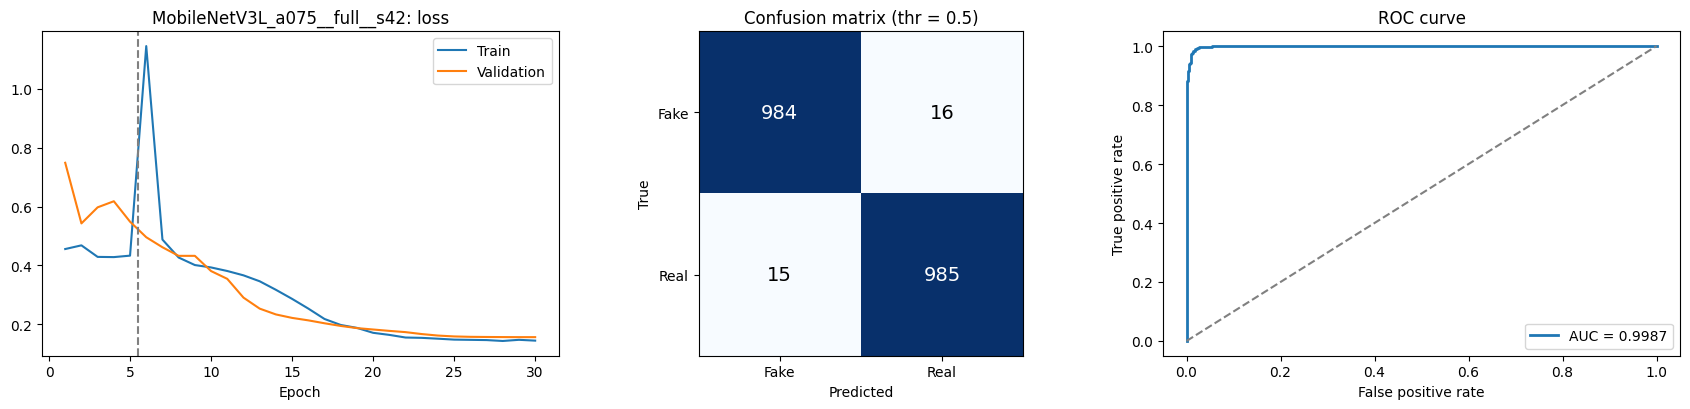

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

DeFakeNet_NR__full__s1: 25,664,001 params | changes vs full recipe: none
Epoch 1/5
188/188 - 46s - 247ms/step - accuracy: 0.7927 - auc: 0.8803 - loss: 0.4985 - val_accuracy: 0.7125 - val_auc: 0.8258 - val_loss: 0.5842
Epoch 2/5
188/188 - 36s - 194ms/step - accuracy: 0.8183 - auc: 0.9021 - loss: 0.4396 - val_accuracy: 0.5535 - val_auc: 0.8370 - val_loss: 0.8256
Epoch 3/5
188/188 - 36s - 194ms/step - accuracy: 0.8132 - auc: 0.9012 - loss: 0.4475 - val_accuracy: 0.6435 - val_auc: 0.8443 - val_loss: 0.6498
Epoch 4/5
188/188 - 37s - 195ms/step - accuracy: 0.8303 - auc: 0.9132 - loss: 0.4244 - val_accuracy: 0.6025 - val_auc: 0.8635 - val_loss: 0.6863
Epoch 5/5
188/188 - 36s - 194ms/step - accuracy: 0.8330 - auc: 0.9161 - loss: 0.4225 - val_accuracy: 0.7265 - val_auc: 0.8682 - val_loss: 0.5414
Epoch 1/25
  EMA  val_loss 0.4012 | val_acc 0.8310 | val_auc 0.9352
188/188 - 163s - 867ms/step - accuracy: 0.6385 - auc: 0.6197 - loss: 0.8983
Epoch 

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 50.45 | AUC 46.18


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 47.90 | AUC 17.76


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.25 | AUC 99.74
INFO:tensorflow:Assets written to: /tmp/tmp_xlhaez6/assets


INFO:tensorflow:Assets written to: /tmp/tmp_xlhaez6/assets


-> DeFakeNet_NR__full__s1: acc 98.35 | TTA 98.80 | AUC 99.85 | MCC 96.70 | 25.66 M | 52.1 min | CPU b1 85 ms
              precision    recall  f1-score   support

        Fake     0.9821    0.9850    0.9835      1000
        Real     0.9850    0.9820    0.9835      1000

    accuracy                         0.9835      2000
   macro avg     0.9835    0.9835    0.9835      2000
weighted avg     0.9835    0.9835    0.9835      2000



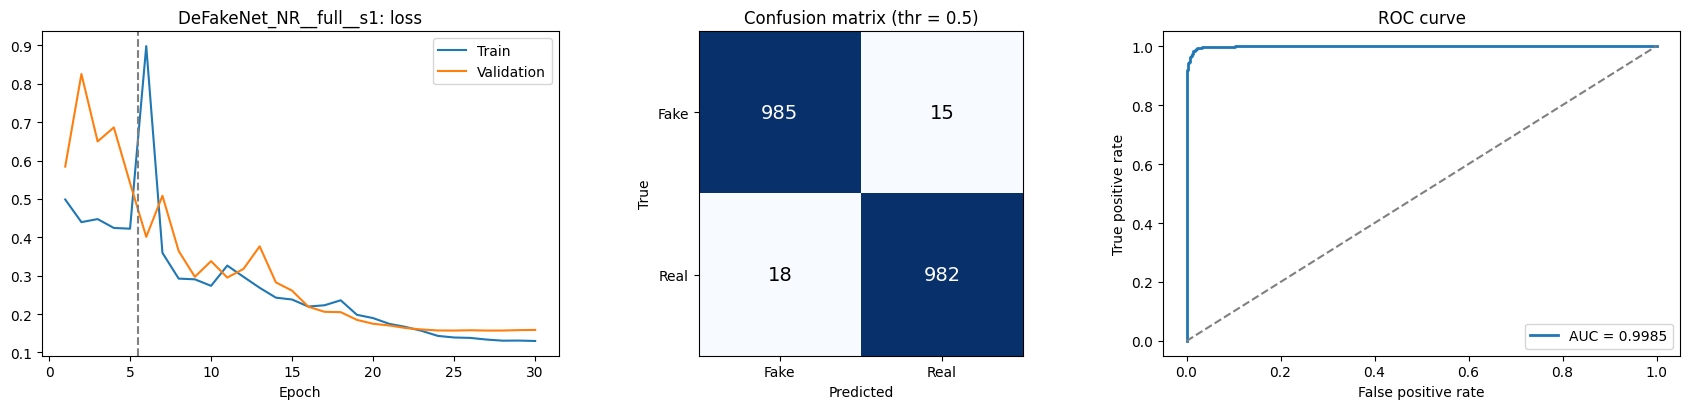


DeFakeNet_NR__paper01__s42: 25,664,001 params | changes vs full recipe: {'scale': '01'}
Epoch 1/5
188/188 - 45s - 241ms/step - accuracy: 0.7918 - auc: 0.8774 - loss: 0.4956 - val_accuracy: 0.6540 - val_auc: 0.8068 - val_loss: 0.6617
Epoch 2/5
188/188 - 36s - 193ms/step - accuracy: 0.8095 - auc: 0.8926 - loss: 0.4580 - val_accuracy: 0.6580 - val_auc: 0.8185 - val_loss: 0.6366
Epoch 3/5
188/188 - 37s - 194ms/step - accuracy: 0.8222 - auc: 0.9044 - loss: 0.4374 - val_accuracy: 0.6885 - val_auc: 0.8355 - val_loss: 0.6001
Epoch 4/5
188/188 - 37s - 194ms/step - accuracy: 0.8262 - auc: 0.9093 - loss: 0.4281 - val_accuracy: 0.5805 - val_auc: 0.8535 - val_loss: 0.7399
Epoch 5/5
188/188 - 36s - 193ms/step - accuracy: 0.8260 - auc: 0.9068 - loss: 0.4387 - val_accuracy: 0.7055 - val_auc: 0.8554 - val_loss: 0.5881
Epoch 1/25
  EMA  val_loss 0.4609 | val_acc 0.8275 | val_auc 0.9057
188/188 - 155s - 826ms/step - accuracy: 0.6130 - auc: 0.5449 - loss: 1.0402
Epoch 2/25
  EMA  val_loss 0.4342 | val_ac

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 50.35 | AUC 51.10


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 47.75 | AUC 45.98


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.15 | AUC 99.87
INFO:tensorflow:Assets written to: /tmp/tmpgvycjiz8/assets


INFO:tensorflow:Assets written to: /tmp/tmpgvycjiz8/assets


-> DeFakeNet_NR__paper01__s42: acc 98.40 | TTA 98.70 | AUC 99.83 | MCC 96.80 | 25.66 M | 51.8 min | CPU b1 81 ms
              precision    recall  f1-score   support

        Fake     0.9850    0.9830    0.9840      1000
        Real     0.9830    0.9850    0.9840      1000

    accuracy                         0.9840      2000
   macro avg     0.9840    0.9840    0.9840      2000
weighted avg     0.9840    0.9840    0.9840      2000



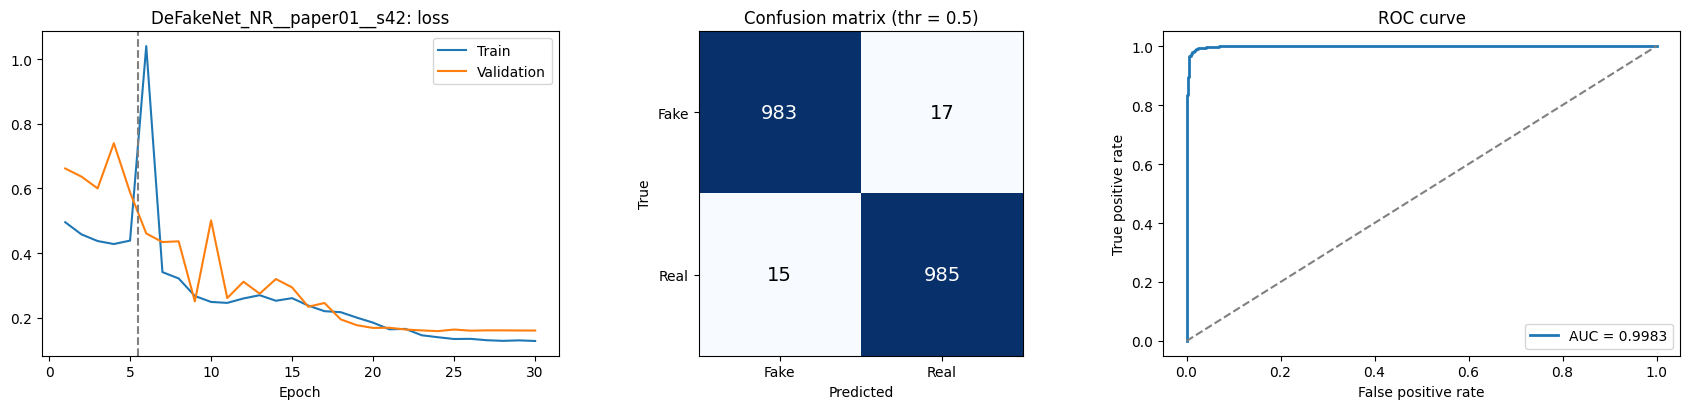

Found 6000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.

MobileNetV3L_a075__size224__s42: 1,901,153 params | changes vs full recipe: {'img': 224}
Epoch 1/5
188/188 - 21s - 113ms/step - accuracy: 0.7975 - auc: 0.8793 - loss: 0.4655 - val_accuracy: 0.5635 - val_auc: 0.8238 - val_loss: 0.7417
Epoch 2/5
188/188 - 11s - 61ms/step - accuracy: 0.8042 - auc: 0.8854 - loss: 0.4728 - val_accuracy: 0.6715 - val_auc: 0.8416 - val_loss: 0.5978
Epoch 3/5
188/188 - 12s - 61ms/step - accuracy: 0.8232 - auc: 0.9002 - loss: 0.4466 - val_accuracy: 0.6195 - val_auc: 0.8534 - val_loss: 0.6607
Epoch 4/5
188/188 - 11s - 60ms/step - accuracy: 0.8117 - auc: 0.8965 - loss: 0.4486 - val_accuracy: 0.6510 - val_auc: 0.8504 - val_loss: 0.6404
Epoch 5/5
188/188 - 11s - 59ms/step - accuracy: 0.8233 - auc: 0.9068 - loss: 0.4302 - val_accuracy: 0.7095 - val_auc: 0.8686 - val_loss: 0.5627
Epoch 1/25
  EMA  val_loss 0.5296 | val_acc 0.7620 | val_auc 0.877

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 49.30 | AUC 50.50


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 48.75 | AUC 15.27


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 97.70 | AUC 99.80
INFO:tensorflow:Assets written to: /tmp/tmpr14jkce3/assets


INFO:tensorflow:Assets written to: /tmp/tmpr14jkce3/assets


-> MobileNetV3L_a075__size224__s42: acc 98.00 | TTA 98.00 | AUC 99.67 | MCC 96.00 | 1.90 M | 20.0 min | CPU b1 24 ms
              precision    recall  f1-score   support

        Fake     0.9819    0.9780    0.9800      1000
        Real     0.9781    0.9820    0.9800      1000

    accuracy                         0.9800      2000
   macro avg     0.9800    0.9800    0.9800      2000
weighted avg     0.9800    0.9800    0.9800      2000



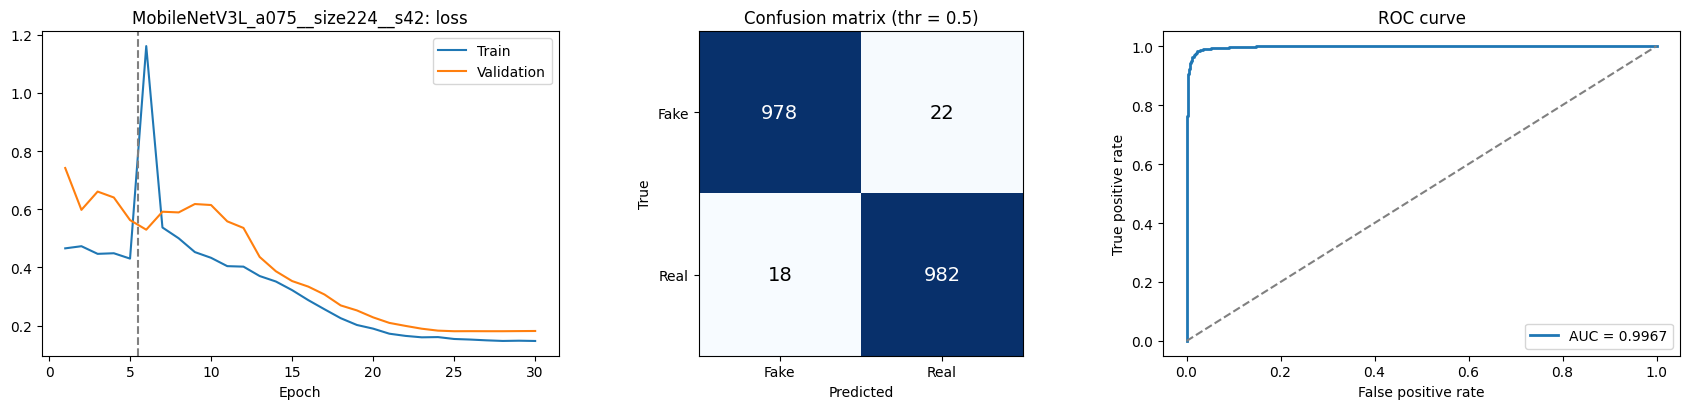

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



MobileNetV3L_a075__heavyAug__s42: 1,901,153 params | changes vs full recipe: {'aug': 'heavy'}
Epoch 1/5
188/188 - 23s - 121ms/step - accuracy: 0.7658 - auc: 0.8511 - loss: 0.4995 - val_accuracy: 0.5015 - val_auc: 0.7562 - val_loss: 0.8624
Epoch 2/5
188/188 - 15s - 78ms/step - accuracy: 0.7638 - auc: 0.8408 - loss: 0.5276 - val_accuracy: 0.5005 - val_auc: 0.7390 - val_loss: 0.9192
Epoch 3/5
188/188 - 15s - 78ms/step - accuracy: 0.7577 - auc: 0.8356 - loss: 0.5301 - val_accuracy: 0.5010 - val_auc: 0.7539 - val_loss: 0.9195
Epoch 4/5
188/188 - 14s - 77ms/step - accuracy: 0.7663 - auc: 0.8388 - loss: 0.5269 - val_accuracy: 0.5035 - val_auc: 0.7543 - val_loss: 0.8797
Epoch 5/5
188/188 - 14s - 77ms/step - accuracy: 0.7637 - auc: 0.8395 - loss: 0.5254 - val_accuracy: 0.5070 - val_auc: 0.7497 - val_loss: 0.8607
Epoch 1/25
  EMA  val_loss 0.6006 | val_acc 0.6965 | val_auc 0.7860
188/188 - 94s - 499ms/step - accuracy: 0.5012 - auc: 0.3689 - loss: 1.2811
Epoch 2/25
  EMA  val_loss 0.5976 | val_a

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 49.25 | AUC 57.46


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 47.65 | AUC 22.44


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 95.05 | AUC 98.97
INFO:tensorflow:Assets written to: /tmp/tmp_8s1o25g/assets


INFO:tensorflow:Assets written to: /tmp/tmp_8s1o25g/assets


-> MobileNetV3L_a075__heavyAug__s42: acc 94.60 | TTA 94.65 | AUC 98.89 | MCC 89.22 | 1.90 M | 24.9 min | CPU b1 28 ms
              precision    recall  f1-score   support

        Fake     0.9551    0.9360    0.9455      1000
        Real     0.9373    0.9560    0.9465      1000

    accuracy                         0.9460      2000
   macro avg     0.9462    0.9460    0.9460      2000
weighted avg     0.9462    0.9460    0.9460      2000



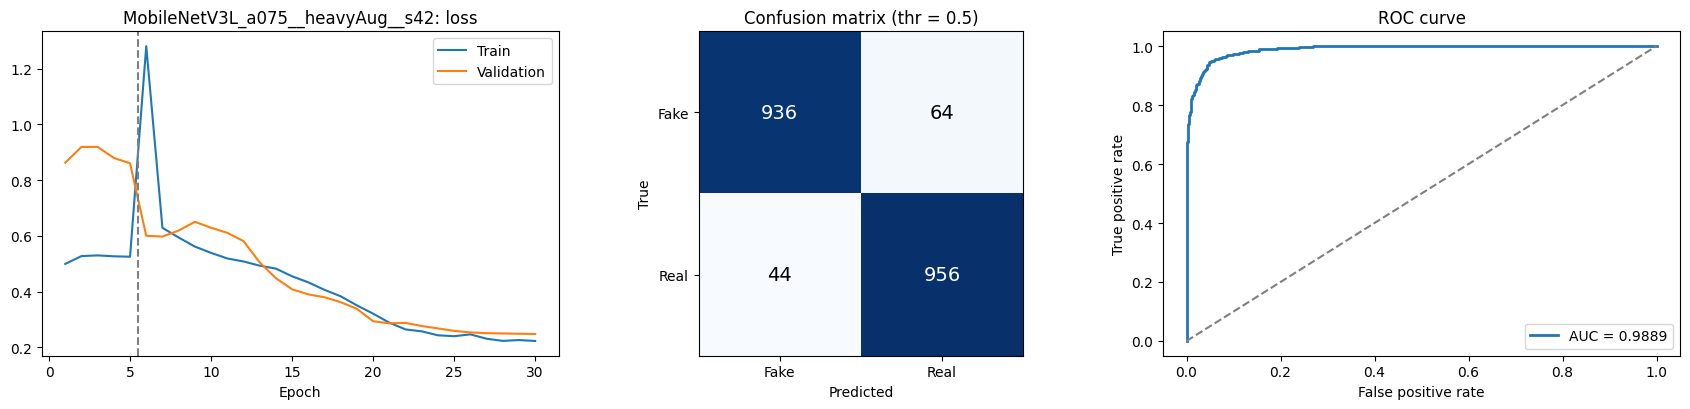

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



MobileNetV3L_a075__noWarmup__s42: 1,901,153 params | changes vs full recipe: {'warmup': 0, 'ft': 30}
Epoch 1/30
  EMA  val_loss 0.6560 | val_acc 0.6185 | val_auc 0.6746
188/188 - 92s - 488ms/step - accuracy: 0.7312 - auc: 0.7838 - loss: 0.5753
Epoch 2/30
  EMA  val_loss 0.6256 | val_acc 0.6395 | val_auc 0.8209
188/188 - 53s - 282ms/step - accuracy: 0.7713 - auc: 0.8525 - loss: 0.5073
Epoch 3/30
  EMA  val_loss 0.6043 | val_acc 0.6930 | val_auc 0.9406
188/188 - 53s - 282ms/step - accuracy: 0.8033 - auc: 0.8878 - loss: 0.4605
Epoch 4/30
  EMA  val_loss 0.6598 | val_acc 0.7055 | val_auc 0.9758
188/188 - 53s - 282ms/step - accuracy: 0.8255 - auc: 0.8812 - loss: 0.4584
Epoch 5/30
  EMA  val_loss 0.5924 | val_acc 0.7870 | val_auc 0.9872
188/188 - 53s - 282ms/step - accuracy: 0.8393 - auc: 0.8982 - loss: 0.4242
Epoch 6/30
  EMA  val_loss 0.6094 | val_acc 0.8110 | val_auc 0.9889
188/188 - 53s - 282ms/step - accuracy: 0.8660 - auc: 0.9299 - loss: 0.3824
Epoch 7/30
  EMA  val_loss 0.4810 | val_

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 50.00 | AUC 51.90


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 48.45 | AUC 54.41


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.90 | AUC 99.96
INFO:tensorflow:Assets written to: /tmp/tmpbkrum8fu/assets


INFO:tensorflow:Assets written to: /tmp/tmpbkrum8fu/assets


-> MobileNetV3L_a075__noWarmup__s42: acc 99.05 | TTA 99.15 | AUC 99.96 | MCC 98.11 | 1.90 M | 27.2 min | CPU b1 29 ms
              precision    recall  f1-score   support

        Fake     0.9970    0.9840    0.9904      1000
        Real     0.9842    0.9970    0.9906      1000

    accuracy                         0.9905      2000
   macro avg     0.9906    0.9905    0.9905      2000
weighted avg     0.9906    0.9905    0.9905      2000



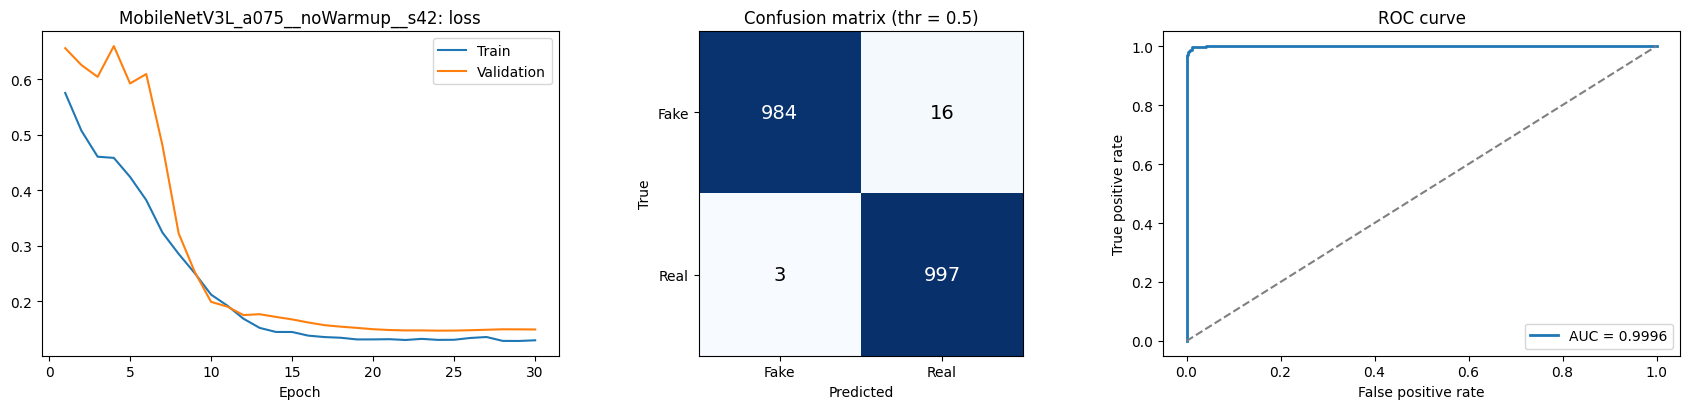

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



MobileNetV3L_a075__noEMA__s42: 1,901,153 params | changes vs full recipe: {'ema': 0.0}
Epoch 1/5
188/188 - 22s - 116ms/step - accuracy: 0.8023 - auc: 0.8865 - loss: 0.4569 - val_accuracy: 0.6295 - val_auc: 0.8526 - val_loss: 0.6415
Epoch 2/5
188/188 - 14s - 76ms/step - accuracy: 0.8133 - auc: 0.8947 - loss: 0.4588 - val_accuracy: 0.6735 - val_auc: 0.8546 - val_loss: 0.6185
Epoch 3/5
188/188 - 14s - 76ms/step - accuracy: 0.8267 - auc: 0.9052 - loss: 0.4399 - val_accuracy: 0.7260 - val_auc: 0.8719 - val_loss: 0.5516
Epoch 4/5
188/188 - 14s - 75ms/step - accuracy: 0.8378 - auc: 0.9124 - loss: 0.4252 - val_accuracy: 0.7035 - val_auc: 0.8768 - val_loss: 0.5816
Epoch 5/5
188/188 - 14s - 75ms/step - accuracy: 0.8405 - auc: 0.9160 - loss: 0.4184 - val_accuracy: 0.7815 - val_auc: 0.8865 - val_loss: 0.4901
Epoch 1/25
  EMA  val_loss 0.5421 | val_acc 0.7475 | val_auc 0.8899
188/188 - 91s - 486ms/step - accuracy: 0.5337 - auc: 0.4838 - loss: 1.0494
Epoch 2/25
  EMA  val_loss 0.5332 | val_acc 0.76

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 52.55 | AUC 55.64


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 49.05 | AUC 39.55


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.75 | AUC 99.95
INFO:tensorflow:Assets written to: /tmp/tmp728twclw/assets


INFO:tensorflow:Assets written to: /tmp/tmp728twclw/assets


-> MobileNetV3L_a075__noEMA__s42: acc 98.50 | TTA 98.65 | AUC 99.90 | MCC 97.00 | 1.90 M | 24.2 min | CPU b1 30 ms
              precision    recall  f1-score   support

        Fake     0.9889    0.9810    0.9849      1000
        Real     0.9812    0.9890    0.9851      1000

    accuracy                         0.9850      2000
   macro avg     0.9850    0.9850    0.9850      2000
weighted avg     0.9850    0.9850    0.9850      2000



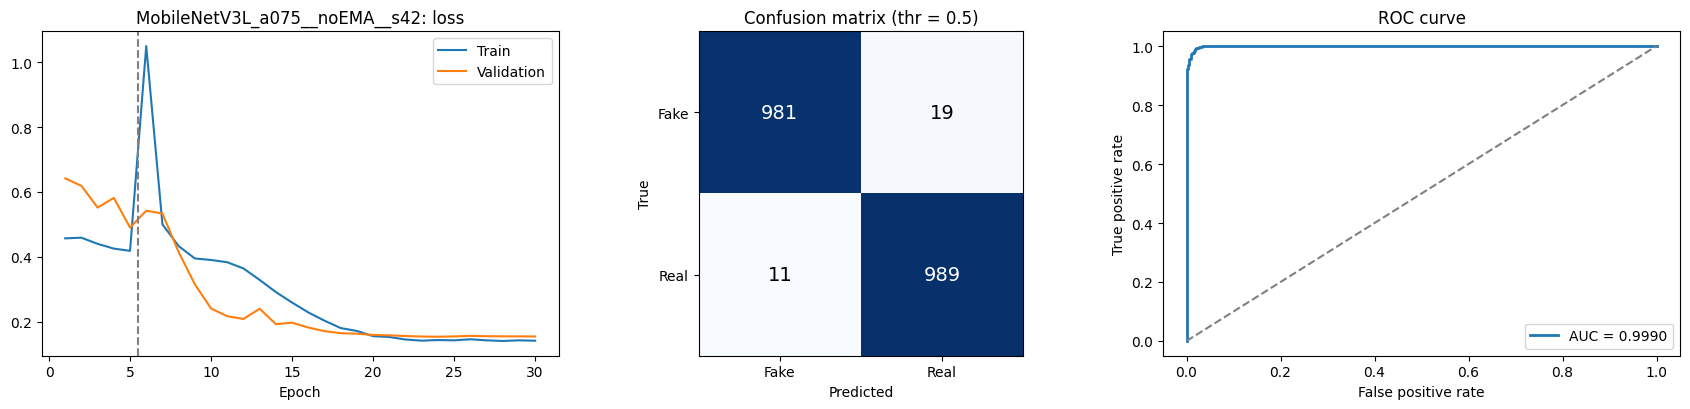

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



MobileNetV3L_a075__trainBN__s42: 1,901,153 params | changes vs full recipe: {'freeze_bn': False}
Epoch 1/5
188/188 - 22s - 116ms/step - accuracy: 0.8077 - auc: 0.8876 - loss: 0.4547 - val_accuracy: 0.6885 - val_auc: 0.8498 - val_loss: 0.5840
Epoch 2/5
188/188 - 14s - 76ms/step - accuracy: 0.8188 - auc: 0.9028 - loss: 0.4450 - val_accuracy: 0.6665 - val_auc: 0.8648 - val_loss: 0.6318
Epoch 3/5
188/188 - 14s - 76ms/step - accuracy: 0.8210 - auc: 0.9024 - loss: 0.4461 - val_accuracy: 0.7260 - val_auc: 0.8707 - val_loss: 0.5636
Epoch 4/5
188/188 - 14s - 75ms/step - accuracy: 0.8368 - auc: 0.9144 - loss: 0.4208 - val_accuracy: 0.7110 - val_auc: 0.8816 - val_loss: 0.5613
Epoch 5/5
188/188 - 14s - 74ms/step - accuracy: 0.8373 - auc: 0.9159 - loss: 0.4214 - val_accuracy: 0.7395 - val_auc: 0.8839 - val_loss: 0.5446
Epoch 1/25
  EMA  val_loss 0.5003 | val_acc 0.7815 | val_auc 0.8921
188/188 - 92s - 487ms/step - accuracy: 0.5180 - auc: 0.4381 - loss: 1.2755
Epoch 2/25
  EMA  val_loss 0.4901 | va

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 51.70 | AUC 53.60


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 49.20 | AUC 43.88


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.80 | AUC 99.94
INFO:tensorflow:Assets written to: /tmp/tmppqj65ab1/assets


INFO:tensorflow:Assets written to: /tmp/tmppqj65ab1/assets


-> MobileNetV3L_a075__trainBN__s42: acc 98.25 | TTA 98.45 | AUC 99.82 | MCC 96.50 | 1.90 M | 24.2 min | CPU b1 30 ms
              precision    recall  f1-score   support

        Fake     0.9801    0.9850    0.9825      1000
        Real     0.9849    0.9800    0.9825      1000

    accuracy                         0.9825      2000
   macro avg     0.9825    0.9825    0.9825      2000
weighted avg     0.9825    0.9825    0.9825      2000



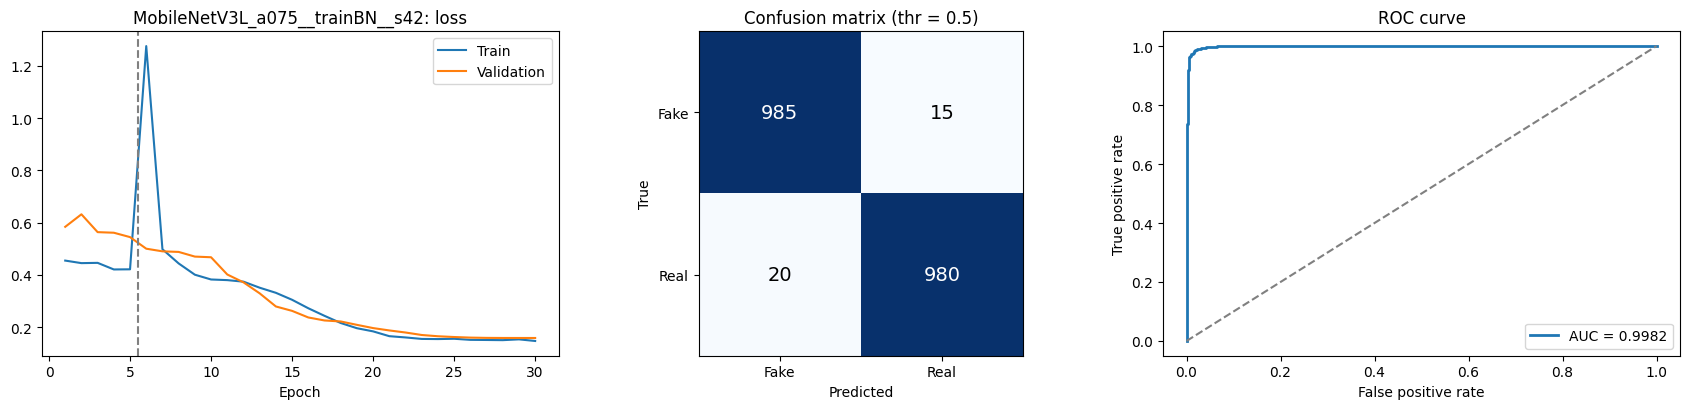

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



MobileNetV3L_a075__noLS__s42: 1,901,153 params | changes vs full recipe: {'label_smooth': 0.0}
Epoch 1/5
188/188 - 22s - 117ms/step - accuracy: 0.7875 - auc: 0.8681 - loss: 0.4873 - val_accuracy: 0.6040 - val_auc: 0.8220 - val_loss: 0.6626
Epoch 2/5
188/188 - 14s - 77ms/step - accuracy: 0.7850 - auc: 0.8638 - loss: 0.4750 - val_accuracy: 0.6595 - val_auc: 0.8319 - val_loss: 0.6036
Epoch 3/5
188/188 - 14s - 77ms/step - accuracy: 0.8073 - auc: 0.8814 - loss: 0.4490 - val_accuracy: 0.5995 - val_auc: 0.8507 - val_loss: 0.6816
Epoch 4/5
188/188 - 14s - 75ms/step - accuracy: 0.8018 - auc: 0.8782 - loss: 0.4483 - val_accuracy: 0.6665 - val_auc: 0.8619 - val_loss: 0.5956
Epoch 5/5
188/188 - 14s - 75ms/step - accuracy: 0.8180 - auc: 0.8985 - loss: 0.4130 - val_accuracy: 0.6915 - val_auc: 0.8542 - val_loss: 0.5984
Epoch 1/25
  EMA  val_loss 0.4846 | val_acc 0.7700 | val_auc 0.8689
188/188 - 92s - 488ms/step - accuracy: 0.5202 - auc: 0.4154 - loss: 1.3656
Epoch 2/25
  EMA  val_loss 0.5007 | val_

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 53.90 | AUC 57.53


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 49.40 | AUC 48.12


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.60 | AUC 99.94
INFO:tensorflow:Assets written to: /tmp/tmp6l6y3syp/assets


INFO:tensorflow:Assets written to: /tmp/tmp6l6y3syp/assets


-> MobileNetV3L_a075__noLS__s42: acc 98.60 | TTA 98.75 | AUC 99.90 | MCC 97.20 | 1.90 M | 24.2 min | CPU b1 29 ms
              precision    recall  f1-score   support

        Fake     0.9841    0.9880    0.9860      1000
        Real     0.9880    0.9840    0.9860      1000

    accuracy                         0.9860      2000
   macro avg     0.9860    0.9860    0.9860      2000
weighted avg     0.9860    0.9860    0.9860      2000



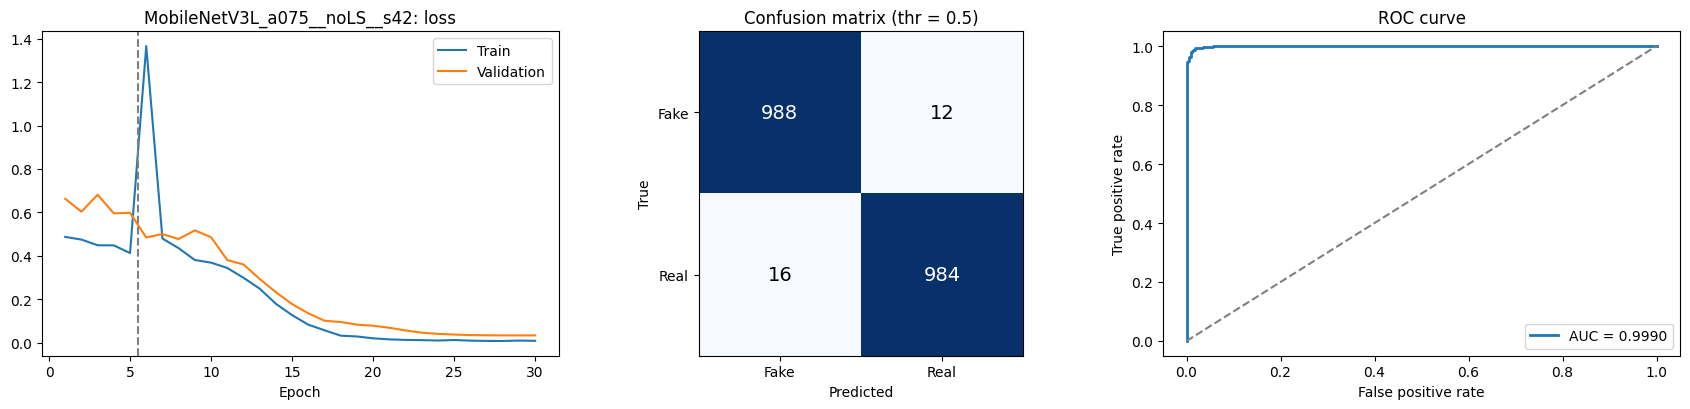

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



MobileNetV3L_a075__plainAdam__s42: 1,901,153 params | changes vs full recipe: {'opt': 'adam_const'}
Epoch 1/5
188/188 - 22s - 116ms/step - accuracy: 0.8017 - auc: 0.8852 - loss: 0.4572 - val_accuracy: 0.6610 - val_auc: 0.8431 - val_loss: 0.6213
Epoch 2/5
188/188 - 14s - 77ms/step - accuracy: 0.8177 - auc: 0.8990 - loss: 0.4506 - val_accuracy: 0.7010 - val_auc: 0.8689 - val_loss: 0.5805
Epoch 3/5
188/188 - 14s - 76ms/step - accuracy: 0.8238 - auc: 0.9023 - loss: 0.4450 - val_accuracy: 0.7425 - val_auc: 0.8770 - val_loss: 0.5339
Epoch 4/5
188/188 - 14s - 75ms/step - accuracy: 0.8303 - auc: 0.9095 - loss: 0.4300 - val_accuracy: 0.7090 - val_auc: 0.8848 - val_loss: 0.5689
Epoch 5/5
188/188 - 14s - 75ms/step - accuracy: 0.8372 - auc: 0.9157 - loss: 0.4211 - val_accuracy: 0.7405 - val_auc: 0.8833 - val_loss: 0.5458
Epoch 1/25
  EMA  val_loss 0.4903 | val_acc 0.7915 | val_auc 0.8883
188/188 - 81s - 429ms/step - accuracy: 0.7240 - auc: 0.7553 - loss: 0.6751
Epoch 2/25
  EMA  val_loss 0.4507 |

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 54.25 | AUC 58.14


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 48.65 | AUC 51.83


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 99.15 | AUC 99.96
INFO:tensorflow:Assets written to: /tmp/tmptosmn0yv/assets


INFO:tensorflow:Assets written to: /tmp/tmptosmn0yv/assets


-> MobileNetV3L_a075__plainAdam__s42: acc 99.05 | TTA 99.00 | AUC 99.96 | MCC 98.11 | 1.90 M | 23.1 min | CPU b1 30 ms
              precision    recall  f1-score   support

        Fake     0.9960    0.9850    0.9904      1000
        Real     0.9852    0.9960    0.9906      1000

    accuracy                         0.9905      2000
   macro avg     0.9906    0.9905    0.9905      2000
weighted avg     0.9906    0.9905    0.9905      2000



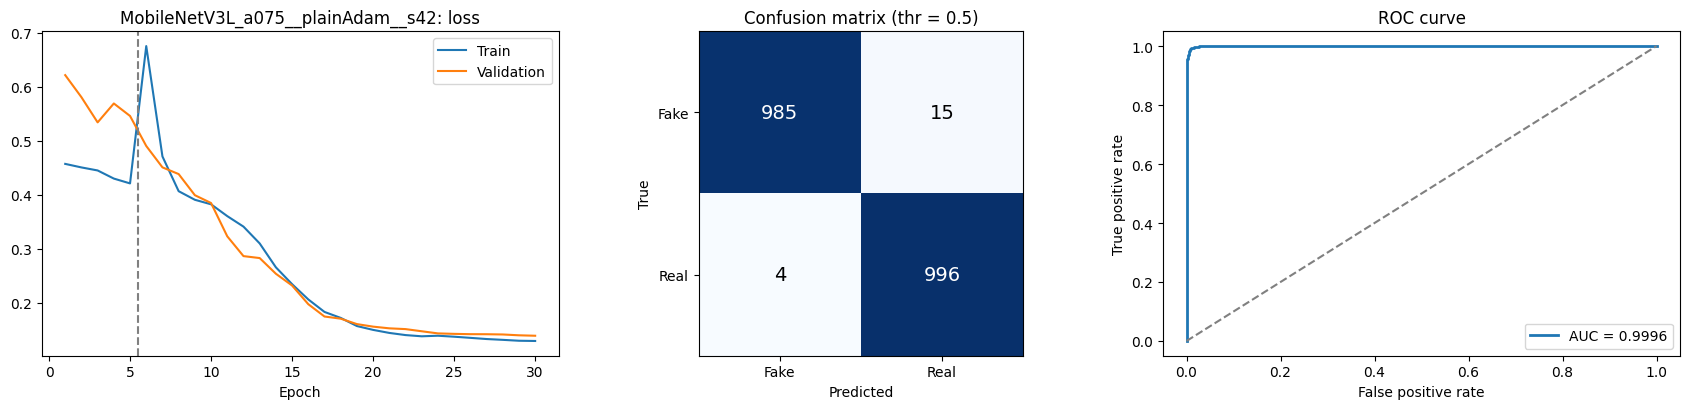

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



MobileNetV3L_a075__full__s1: 1,901,153 params | changes vs full recipe: none
Epoch 1/5
188/188 - 22s - 116ms/step - accuracy: 0.7902 - auc: 0.8726 - loss: 0.4811 - val_accuracy: 0.6940 - val_auc: 0.8442 - val_loss: 0.5780
Epoch 2/5
188/188 - 14s - 76ms/step - accuracy: 0.8150 - auc: 0.8947 - loss: 0.4557 - val_accuracy: 0.6660 - val_auc: 0.8615 - val_loss: 0.6028
Epoch 3/5
188/188 - 14s - 76ms/step - accuracy: 0.8273 - auc: 0.9060 - loss: 0.4345 - val_accuracy: 0.7100 - val_auc: 0.8705 - val_loss: 0.5690
Epoch 4/5
188/188 - 14s - 75ms/step - accuracy: 0.8382 - auc: 0.9167 - loss: 0.4188 - val_accuracy: 0.6985 - val_auc: 0.8789 - val_loss: 0.5919
Epoch 5/5
188/188 - 14s - 75ms/step - accuracy: 0.8268 - auc: 0.9053 - loss: 0.4364 - val_accuracy: 0.6635 - val_auc: 0.8773 - val_loss: 0.6360
Epoch 1/25
  EMA  val_loss 0.4952 | val_acc 0.7725 | val_auc 0.8872
188/188 - 92s - 488ms/step - accuracy: 0.5228 - auc: 0.4092 - loss: 1.4209
Epoch 2/25
  EMA  val_loss 0.4918 | val_acc 0.7855 | val_a

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 51.45 | AUC 55.91


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 49.00 | AUC 31.13


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.55 | AUC 99.94
INFO:tensorflow:Assets written to: /tmp/tmp0qr6ybk9/assets


INFO:tensorflow:Assets written to: /tmp/tmp0qr6ybk9/assets


-> MobileNetV3L_a075__full__s1: acc 98.30 | TTA 98.55 | AUC 99.87 | MCC 96.61 | 1.90 M | 24.3 min | CPU b1 31 ms
              precision    recall  f1-score   support

        Fake     0.9899    0.9760    0.9829      1000
        Real     0.9763    0.9900    0.9831      1000

    accuracy                         0.9830      2000
   macro avg     0.9831    0.9830    0.9830      2000
weighted avg     0.9831    0.9830    0.9830      2000



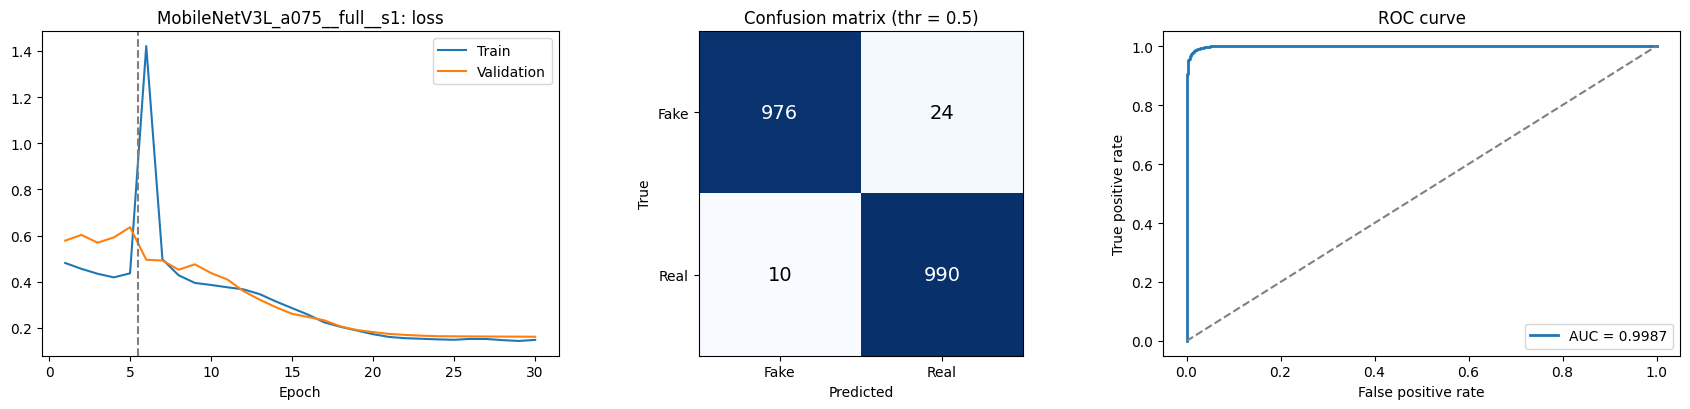

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



MobileNetV3L_a075__full__s2: 1,901,153 params | changes vs full recipe: none
Epoch 1/5
188/188 - 22s - 116ms/step - accuracy: 0.7940 - auc: 0.8819 - loss: 0.4635 - val_accuracy: 0.6875 - val_auc: 0.8209 - val_loss: 0.6135
Epoch 2/5
188/188 - 14s - 76ms/step - accuracy: 0.8123 - auc: 0.8889 - loss: 0.4662 - val_accuracy: 0.6840 - val_auc: 0.8602 - val_loss: 0.5903
Epoch 3/5
188/188 - 14s - 75ms/step - accuracy: 0.8163 - auc: 0.8970 - loss: 0.4516 - val_accuracy: 0.6345 - val_auc: 0.8595 - val_loss: 0.6732
Epoch 4/5
188/188 - 14s - 75ms/step - accuracy: 0.8223 - auc: 0.9007 - loss: 0.4470 - val_accuracy: 0.7065 - val_auc: 0.8727 - val_loss: 0.5631
Epoch 5/5
188/188 - 14s - 74ms/step - accuracy: 0.8352 - auc: 0.9120 - loss: 0.4252 - val_accuracy: 0.7115 - val_auc: 0.8813 - val_loss: 0.5679
Epoch 1/25
  EMA  val_loss 0.4980 | val_acc 0.7830 | val_auc 0.8858
188/188 - 92s - 490ms/step - accuracy: 0.5208 - auc: 0.4137 - loss: 1.2545
Epoch 2/25
  EMA  val_loss 0.5021 | val_acc 0.7845 | val_a

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 56.10 | AUC 59.10


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 49.10 | AUC 37.38


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 99.10 | AUC 99.95
INFO:tensorflow:Assets written to: /tmp/tmp8986vzir/assets


INFO:tensorflow:Assets written to: /tmp/tmp8986vzir/assets


-> MobileNetV3L_a075__full__s2: acc 98.35 | TTA 98.50 | AUC 99.87 | MCC 96.70 | 1.90 M | 24.3 min | CPU b1 31 ms
              precision    recall  f1-score   support

        Fake     0.9840    0.9830    0.9835      1000
        Real     0.9830    0.9840    0.9835      1000

    accuracy                         0.9835      2000
   macro avg     0.9835    0.9835    0.9835      2000
weighted avg     0.9835    0.9835    0.9835      2000



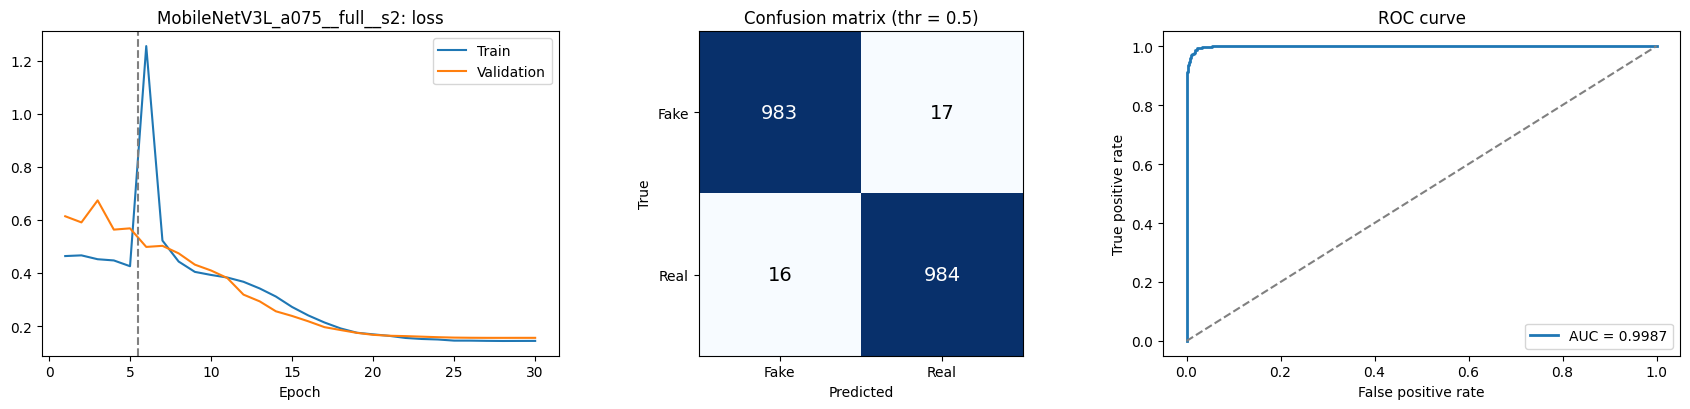


DeFakeNet_NR__full__s2: 25,664,001 params | changes vs full recipe: none
Epoch 1/5
188/188 - 45s - 242ms/step - accuracy: 0.7888 - auc: 0.8731 - loss: 0.5240 - val_accuracy: 0.6235 - val_auc: 0.8270 - val_loss: 0.6414
Epoch 2/5
188/188 - 36s - 194ms/step - accuracy: 0.8147 - auc: 0.8981 - loss: 0.4512 - val_accuracy: 0.6750 - val_auc: 0.8372 - val_loss: 0.6139
Epoch 3/5
188/188 - 36s - 193ms/step - accuracy: 0.8305 - auc: 0.9113 - loss: 0.4270 - val_accuracy: 0.6330 - val_auc: 0.8451 - val_loss: 0.7023
Epoch 4/5
188/188 - 37s - 194ms/step - accuracy: 0.8280 - auc: 0.9073 - loss: 0.4358 - val_accuracy: 0.7000 - val_auc: 0.8517 - val_loss: 0.5935
Epoch 5/5
188/188 - 36s - 194ms/step - accuracy: 0.8312 - auc: 0.9168 - loss: 0.4165 - val_accuracy: 0.6740 - val_auc: 0.8546 - val_loss: 0.6588
Epoch 1/25
  EMA  val_loss 0.4420 | val_acc 0.8065 | val_auc 0.9119
188/188 - 155s - 826ms/step - accuracy: 0.6117 - auc: 0.5386 - loss: 1.0596
Epoch 2/25
  EMA  val_loss 0.3157 | val_acc 0.9000 | val_

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 49.70 | AUC 45.81


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 47.90 | AUC 63.68


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 97.95 | AUC 99.79
INFO:tensorflow:Assets written to: /tmp/tmpc32jzw7a/assets


INFO:tensorflow:Assets written to: /tmp/tmpc32jzw7a/assets


-> DeFakeNet_NR__full__s2: acc 98.70 | TTA 98.70 | AUC 99.88 | MCC 97.40 | 25.66 M | 51.9 min | CPU b1 88 ms
              precision    recall  f1-score   support

        Fake     0.9880    0.9860    0.9870      1000
        Real     0.9860    0.9880    0.9870      1000

    accuracy                         0.9870      2000
   macro avg     0.9870    0.9870    0.9870      2000
weighted avg     0.9870    0.9870    0.9870      2000



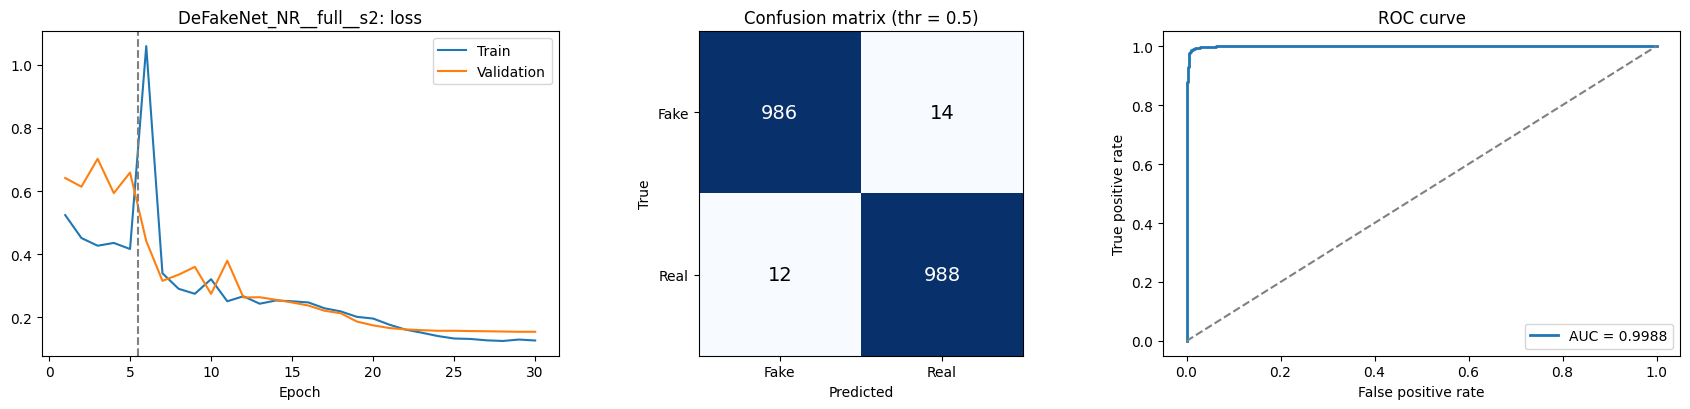

finished runs: 13 of 13


In [9]:
RESULTS = {}
for g, n, t, s, o in RUNS:
    key = f"{n}__{t}__s{s}"; path = f"{OUTDIR}/{key}_results.json"
    try:
        if os.path.exists(path):
            RESULTS[key] = json.load(open(path)); print("loaded", key)
        else:
            RESULTS[key] = run_experiment(n, t, s, o, g)
        show_report(RESULTS[key])
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"!! {key} FAILED: {e!r}")
print("finished runs:", len(RESULTS), "of", len(RUNS))

## 10. Results

Two reference numbers come from earlier single runs on the same test set (threshold 0.5) and are typed in:
- **Old DeFakeNet**: the first single-run reproduction of the paper's recipe, 89.45% accuracy. It is kept here only for comparison; the full reproduction (3 seeds, 90.57 ± 2.18%) is notebook **01**.
- **DeFakeNet_NR seed 42**: an earlier 30-epoch run of this pipeline, 97.90% accuracy, TTA 98.60, AUC 99.80, MCC 95.80.

In [10]:
OLD_DEFAKENET = dict(acc=89.45, auc=97.29, mcc=79.54, f1=88.73, tn=958, tp=831)   # first single-run reproduction
DFN_S42 = dict(acc=97.90, tta=98.60, auc=99.80, mcc=95.80, f1=97.90, tn=978, tp=980)   # earlier 30-epoch run, seed 42
REF_KEY = "MobileNetV3L_a075__full__s42"
from scipy.stats import binomtest

def mcnemar(k1, k2):
    # exact McNemar test on the same 2,000 test images: only the images where the two models disagree count
    c1 = (np.load(f"{OUTDIR}/{k1}_probs.npz")["p_test"] >= 0.5).astype(int) == y_test
    c2 = (np.load(f"{OUTDIR}/{k2}_probs.npz")["p_test"] >= 0.5).astype(int) == y_test
    only1, only2 = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    p = binomtest(min(only1, only2), only1 + only2, 0.5).pvalue if only1 + only2 else 1.0
    return only1, only2, p

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
rows = []
for k, r in RESULTS.items():
    m = r["test"]["thr=0.5"]
    rows.append({"Run": k, "Model": r["model"], "Tag": r["tag"], "Seed": r["seed"], "Params (M)": r["params"]/1e6,
                 "GMACs": r["gmacs"], "Acc %": m["acc"], "Acc % (TTA)": r["test"]["TTA"]["acc"], "AUC %": m["auc"],
                 "MCC %": m["mcc"], "F1 %": m["f1"], "Fakes caught": m["tn"], "Reals caught": m["tp"],
                 "TFLite fp16 MB": r["tflite_mb"], "GPU ms/img b32": r["gpu_ms_b32"], "CPU ms/img b1": r["cpu_ms_b1"],
                 "Train min": r["train_min"], "Best FT epoch": r.get("best_ft_epoch")})
ALL = pd.DataFrame(rows).set_index("Run")
print("All runs (this session, same machine)")
display(ALL.round(2))
ALL.round(3).to_csv(f"{OUTDIR}/all_runs.csv")

All runs (this session, same machine)


,Model,Tag,Seed,Params (M),GMACs,Acc %,Acc % (TTA),AUC %,MCC %,F1 %,Fakes caught,Reals caught,TFLite fp16 MB,GPU ms/img b32,CPU ms/img b1,Train min,Best FT epoch
Run,,,,,,,,,,,,,,,,,
MobileNetV3L_a075__full__s42,MobileNetV3L_a075,full,42,1.90,0.21,98.45,98.75,99.87,96.90,98.45,984,985,3.87,1.43,26.13,24.27,24
DeFakeNet_NR__full__s1,DeFakeNet_NR,full,1,25.66,4.57,98.35,98.80,99.85,96.70,98.35,985,982,51.32,4.14,85.39,52.07,20
DeFakeNet_NR__paper01__s42,DeFakeNet_NR,paper01,42,25.66,4.57,98.40,98.70,99.83,96.80,98.40,983,985,51.32,4.16,81.15,51.80,19
MobileNetV3L_a075__size224__s42,MobileNetV3L_a075,size224,42,1.90,0.16,98.00,98.00,99.67,96.00,98.00,978,982,3.87,1.16,23.99,19.98,20
MobileNetV3L_a075__heavyAug__s42,MobileNetV3L_a075,heavyAug,42,1.90,0.21,94.60,94.65,98.89,89.22,94.65,936,956,3.87,1.43,28.49,24.90,25
MobileNetV3L_a075__noWarmup__s42,MobileNetV3L_a075,noWarmup,42,1.90,0.21,99.05,99.15,99.96,98.11,99.06,984,997,3.87,1.42,28.78,27.22,24
MobileNetV3L_a075__noEMA__s42,MobileNetV3L_a075,noEMA,42,1.90,0.21,98.50,98.65,99.90,97.00,98.51,981,989,3.87,1.47,29.85,24.20,19
MobileNetV3L_a075__trainBN__s42,MobileNetV3L_a075,trainBN,42,1.90,0.21,98.25,98.45,99.82,96.50,98.25,985,980,3.87,1.45,29.93,24.21,23
MobileNetV3L_a075__noLS__s42,MobileNetV3L_a075,noLS,42,1.90,0.21,98.60,98.75,99.90,97.20,98.60,988,984,3.87,1.44,29.36,24.20,23


### 10a. Same machine: small model vs DeFakeNet with the new recipe

Accuracy, speed and size measured in the **same session**, so the timing comparison is fair. The McNemar test uses the same 2,000 test images: p < 0.05 means the accuracy gap is unlikely to be luck.

In [11]:
small = [k for k in RESULTS if RESULTS[k]["model"] == "MobileNetV3L_a075" and RESULTS[k]["tag"] == "full"]
big   = [k for k in RESULTS if RESULTS[k]["model"] == "DeFakeNet_NR" and RESULTS[k]["tag"] == "full"]
if small and big:
    a, b = RESULTS[small[0]], RESULTS[big[0]]
    eff = pd.DataFrame({
        "MobileNetV3L_a075": [a["params"]/1e6, a["gmacs"], a["tflite_mb"], a["cpu_ms_b1"], a["gpu_ms_b32"]],
        "DeFakeNet_NR":      [b["params"]/1e6, b["gmacs"], b["tflite_mb"], b["cpu_ms_b1"], b["gpu_ms_b32"]]},
        index=["Params (M)", "GMACs", "TFLite fp16 MB", "CPU ms/img (batch 1)", "GPU ms/img (batch 32)"])
    eff["DeFakeNet / small (x)"] = eff["DeFakeNet_NR"] / eff["MobileNetV3L_a075"]
    display(eff.round(2)); eff.round(3).to_csv(f"{OUTDIR}/efficiency_same_machine.csv")
    for kb in big:   # pair each DeFakeNet run with the small-model run of the same seed if there is one
        ks = next((k for k in small if RESULTS[k]["seed"] == RESULTS[kb]["seed"]), small[0])
        o1, o2, p = mcnemar(ks, kb)
        print(f"{ks} vs {kb}: acc {RESULTS[ks]['test']['thr=0.5']['acc']:.2f} vs {RESULTS[kb]['test']['thr=0.5']['acc']:.2f} | "
              f"only small right {o1}, only DeFakeNet right {o2} | McNemar p = {p:.4f}")
else:
    print("Needs the 'core' group.")

,MobileNetV3L_a075,DeFakeNet_NR,DeFakeNet / small (x)
Params (M),1.90,25.66,13.50
GMACs,0.21,4.57,22.00
TFLite fp16 MB,3.87,51.32,13.26
CPU ms/img (batch 1),26.13,85.39,3.27
GPU ms/img (batch 32),1.43,4.14,2.90


MobileNetV3L_a075__full__s1 vs DeFakeNet_NR__full__s1: acc 98.30 vs 98.35 | only small right 30, only DeFakeNet right 31 | McNemar p = 1.0000
MobileNetV3L_a075__full__s2 vs DeFakeNet_NR__full__s2: acc 98.35 vs 98.70 | only small right 19, only DeFakeNet right 26 | McNemar p = 0.3713


### 10b. Is the paper's 0-to-1 pixel scaling the problem?

Same DeFakeNet model and the same new recipe; the only change is the pixel scale fed to ResNet50V2.

In [12]:
k01 = "DeFakeNet_NR__paper01__s42"
if k01 in RESULTS:
    m = RESULTS[k01]["test"]["thr=0.5"]
    full = [RESULTS[k]["test"]["thr=0.5"]["acc"] for k in big] + [DFN_S42["acc"]]
    print(f"Old DeFakeNet run (old recipe, 0..1 input):        acc {OLD_DEFAKENET['acc']:.2f}")
    print(f"DeFakeNet, new recipe but 0..1 input (paper's way): acc {m['acc']:.2f} | AUC {m['auc']:.2f} | MCC {m['mcc']:.2f}")
    print(f"DeFakeNet, new recipe, -1..1 input:                 acc {np.mean(full):.2f} (mean of {len(full)} seed(s))")
    print(f"-> effect of the 0..1 scaling alone: {m['acc'] - np.mean(full):+.2f} pt accuracy")
else:
    print("Needs the 'paper_scaling' group.")

Old DeFakeNet run (old recipe, 0..1 input):        acc 89.45
DeFakeNet, new recipe but 0..1 input (paper's way): acc 98.40 | AUC 99.83 | MCC 96.80
DeFakeNet, new recipe, -1..1 input:                 acc 98.32 (mean of 3 seed(s))
-> effect of the 0..1 scaling alone: +0.08 pt accuracy


### 10c. Ablation: which part of the recipe matters?

Each row switches **one** part back to the old way, on the small model, seed 42. A big drop means that part matters. Sorted with the most important part first.

In [13]:
if REF_KEY in RESULTS:
    ref = RESULTS[REF_KEY]["test"]["thr=0.5"]; rows = [{"Switched back to the old way": "nothing (full recipe)",
          "Acc %": ref["acc"], "AUC %": ref["auc"], "MCC %": ref["mcc"], "Δ Acc (pt)": 0.0, "Δ AUC (pt)": 0.0,
          "full right / ablated right": "-", "McNemar p": None}]
    for t, (desc, _) in ABLATIONS.items():
        k = f"MobileNetV3L_a075__{t}__s42"
        if k not in RESULTS: continue
        m = RESULTS[k]["test"]["thr=0.5"]; o1, o2, p = mcnemar(REF_KEY, k)
        rows.append({"Switched back to the old way": desc, "Acc %": m["acc"], "AUC %": m["auc"], "MCC %": m["mcc"],
                     "Δ Acc (pt)": m["acc"] - ref["acc"], "Δ AUC (pt)": m["auc"] - ref["auc"],
                     "full right / ablated right": f"{o1} / {o2}", "McNemar p": round(p, 4)})
    ABL = pd.DataFrame(rows).set_index("Switched back to the old way")
    ABL = pd.concat([ABL.iloc[:1], ABL.iloc[1:].sort_values("Δ Acc (pt)")])
    display(ABL.round(2)); ABL.round(3).to_csv(f"{OUTDIR}/ablation.csv")
    print("Δ < 0 means the model got worse without that part. p < 0.05 means the change is unlikely to be luck.")
else:
    print("Needs the 'core' group (the full-recipe reference run).")

,Acc %,AUC %,MCC %,Δ Acc (pt),Δ AUC (pt),full right / ablated right,McNemar p
Switched back to the old way,,,,,,,
nothing (full recipe),98.45,99.87,96.90,0.00,0.00,-,NaN
"old heavy augmentation (rotate, 20% shift, zoom, upside-down flips)",94.60,98.89,89.22,-3.85,-0.98,92 / 15,0.00
images shrunk to 224 x 224,98.00,99.67,96.00,-0.45,-0.20,25 / 16,0.21
BatchNorm not frozen,98.25,99.82,96.50,-0.20,-0.05,11 / 7,0.48
no EMA weight averaging,98.50,99.90,97.00,0.05,0.03,10 / 11,1.00
no label smoothing,98.60,99.90,97.20,0.15,0.03,10 / 13,0.68
no frozen warm-up (30 epochs of full fine-tuning),99.05,99.96,98.11,0.60,0.09,11 / 23,0.06
plain Adam with a constant learning rate,99.05,99.96,98.11,0.60,0.09,5 / 17,0.02


Δ < 0 means the model got worse without that part. p < 0.05 means the change is unlikely to be luck.


### 10d. Seeds: mean ± std over 3 seeds

DeFakeNet_NR seed 42 comes from the earlier 30-epoch run (typed in); the other seeds are from this session. The final 3-seed results with 40 epochs are in notebook **03**.

In [14]:
def seed_rows(model_name, extra=None):
    ks = [k for k in RESULTS if RESULTS[k]["model"] == model_name and RESULTS[k]["tag"] == "full"]
    vals = {c: [RESULTS[k]["test"]["thr=0.5"][c] for k in ks] for c in ("acc", "auc", "mcc", "f1")}
    vals["tta"] = [RESULTS[k]["test"]["TTA"]["acc"] for k in ks]
    seeds = [RESULTS[k]["seed"] for k in ks]
    if extra:
        for c in vals: vals[c].append(extra[c])
        seeds.append(42)
    return seeds, vals

rows = []
for name, extra in (("MobileNetV3L_a075", None), ("DeFakeNet_NR", DFN_S42)):
    seeds, v = seed_rows(name, extra)
    if not v["acc"]: continue
    fmt = lambda x: f"{np.mean(x):.2f} ± {np.std(x, ddof=1):.2f}" if len(x) > 1 else f"{x[0]:.2f}"
    rows.append({"Model": name, "Seeds": ", ".join(map(str, sorted(seeds))), "Acc %": fmt(v["acc"]),
                 "Acc % (TTA)": fmt(v["tta"]), "AUC %": fmt(v["auc"]), "MCC %": fmt(v["mcc"]), "F1 %": fmt(v["f1"])})
SEEDS_T = pd.DataFrame(rows).set_index("Model")
display(SEEDS_T); SEEDS_T.to_csv(f"{OUTDIR}/seeds_mean_std.csv")
print(f"Old DeFakeNet (one run): {OLD_DEFAKENET['acc']:.2f}% accuracy")

,Seeds,Acc %,Acc % (TTA),AUC %,MCC %,F1 %
Model,,,,,,
MobileNetV3L_a075,"1, 2, 42",98.37 ± 0.08,98.60 ± 0.13,99.87 ± 0.00,96.74 ± 0.15,98.37 ± 0.07
DeFakeNet_NR,"1, 2, 42",98.32 ± 0.40,98.70 ± 0.10,99.84 ± 0.04,96.63 ± 0.80,98.32 ± 0.40


Old DeFakeNet (one run): 89.45% accuracy


### 10e. Cross-dataset test (trained on RVF10K only, no retraining)

AUC is the fairest number here: it does not depend on the 0.5 threshold, which often shifts on a new dataset. Expect big drops; the model that drops **less** generalises better.

In [15]:
if EXTERNAL:
    rows = []
    for k, r in RESULTS.items():
        if r["tag"] not in ("full", "paper01"): continue
        row = {"Run": k, "RVF10K test AUC %": r["test"]["thr=0.5"]["auc"], "RVF10K test Acc %": r["test"]["thr=0.5"]["acc"]}
        for en, m in r["external"].items():
            row[f"{en} AUC %"] = m["auc"]; row[f"{en} Acc %"] = m["acc"]
        rows.append(row)
    XD = pd.DataFrame(rows).set_index("Run")
    display(XD.round(2)); XD.round(3).to_csv(f"{OUTDIR}/cross_dataset_per_run.csv")
    # mean over seeds per model (full recipe only)
    XD2 = XD.loc[[k for k in XD.index if "__full__" in k]].copy()
    XD2["Model"] = [k.split("__")[0] for k in XD2.index]
    agg = XD2.groupby("Model").agg(["mean", "std"]).round(2)
    print("\nMean (and std) over seeds, full recipe:"); display(agg); agg.to_csv(f"{OUTDIR}/cross_dataset_mean.csv")
else:
    print("No extra datasets were attached, so there is no cross-dataset result.")

,RVF10K test AUC %,RVF10K test Acc %,openforensics AUC %,openforensics Acc %,sdxl_faces AUC %,sdxl_faces Acc %,stylegan_140k AUC %,stylegan_140k Acc %
Run,,,,,,,,
MobileNetV3L_a075__full__s42,99.87,98.45,58.33,54.20,45.01,48.50,99.94,98.95
DeFakeNet_NR__full__s1,99.85,98.35,46.18,50.45,17.76,47.90,99.74,98.25
DeFakeNet_NR__paper01__s42,99.83,98.40,51.10,50.35,45.98,47.75,99.87,98.15
MobileNetV3L_a075__full__s1,99.87,98.30,55.91,51.45,31.13,49.00,99.94,98.55
MobileNetV3L_a075__full__s2,99.87,98.35,59.10,56.10,37.38,49.10,99.95,99.10
DeFakeNet_NR__full__s2,99.88,98.70,45.81,49.70,63.68,47.90,99.79,97.95



Mean (and std) over seeds, full recipe:


RVF10K test AUC %       RVF10K test Acc %       openforensics AUC %       openforensics Acc %       sdxl_faces AUC %        sdxl_faces Acc %       stylegan_140k AUC %       stylegan_140k Acc %      
                               mean   std              mean   std                mean   std                mean   std             mean    std             mean   std                mean   std                mean   std
Model                                                                                                                                                                                                                   
DeFakeNet_NR                  99.86  0.02             98.52  0.25               45.99  0.26               50.08  0.53            40.72  32.47            47.90  0.00               99.76  0.03               98.10  0.21
MobileNetV3L_a075             99.87  0.00             98.37  0.08               57.78  1.66               53.92  2.34            37.84   6.95            48.87  0.32               99.95  0.01               98.87  0.28